# Full-throttle speed loss in 2026 F1 qualifying: Japanese GP

Validates FastF1 telemetry for 2026 Japanese GP qualifying (lap distance, frozen car data, usable laps), then measures full-throttle speed loss on three straights and PKE per sector, with teammate and same-PU comparisons and an external check at 130R.

**Sources.** FastF1 3.8.3: *How to perform calculations accurately* guide (HAC), Telemetry API reference (TEL), `fastf1/core.py`. Bopaiah & Samuel (2021), SAE 2021-01-0368. Segers (2014), *Analysis Techniques for Racecar Data Acquisition*, 2nd ed., SAE International.

## 0. Setup

In [1]:
import json
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flatout import *  # pipeline functions, constants (with citations) and caption(); see flatout.py

OFFICIAL_LENGTH_M = 5807  # Suzuka circuit length, formula1.com
WINDOW_130R = (14, 16)    # 130R = Turn 15 (Wikipedia, Suzuka Circuit; F1DA sector breakdown); window T14-T16
OPENF1_SESSION = 11249    # OpenF1 session_key for 2026 Japan qualifying (openf1_session_key(2026, "Japan"))
STALE_TOL = 0.15          # diagnostic only, not a filter (Section 3.5): ~99th percentile of |Speed/RPM deviation| when Speed changed

## 1. Data

2026 Japanese GP qualifying. Corner positions come from `get_circuit_info()`; only their X/Y is used, because its `Distance` column is computed from `laps.pick_fastest()`, which here is a lap with frozen telemetry (Section 3).

In [2]:
s = load_quali(2026, "Japan")
fastest = {d: s.laps.pick_drivers(d).pick_fastest() for d in s.results["Abbreviation"]}
corners = s.get_circuit_info().corners.set_index("Number")
print(f"{s.event['EventName']} {s.name}: {len(fastest)} drivers, {s.laps['LapTime'].notna().sum()} timed laps")

Japanese Grand Prix Qualifying: 22 drivers, 227 timed laps


## 2. Validation 1: lap distance vs official length

Each fastest lap's distance from integrated car-data speed (`add_distance`) and from X/Y path length is compared with the official 5.807 km. Benchmark: < 0.6 % mean and < 1.8 % max error (Bopaiah & Samuel, 2021). X/Y distance meets it; car-data distance does not, because of frozen telemetry (Section 3).

In [3]:
v1 = lap_distance_check(fastest, OFFICIAL_LENGTH_M)
print(v1.round(2).to_string())
print("\n|error| %\n" + v1.filter(like="err%").abs().agg(["mean", "max"]).round(2).to_string())

                   PU  CarData_m     XY_m  CarData_err%  XY_err%
Driver                                                          
ANT          Mercedes    5379.28  5768.67         -7.37    -0.66
RUS          Mercedes    5772.92  5772.07         -0.59    -0.60
PIA          Mercedes    5775.35  5781.66         -0.54    -0.44
LEC           Ferrari    5774.40  5770.77         -0.56    -0.62
NOR          Mercedes    5759.21  5758.98         -0.82    -0.83
HAM           Ferrari    5755.50  5775.74         -0.89    -0.54
GAS          Mercedes    5757.97  5773.84         -0.84    -0.57
HAD     Red Bull Ford    5736.71  5760.63         -1.21    -0.80
BOR              Audi    5839.98  5774.92          0.57    -0.55
LIN     Red Bull Ford    5681.76  5774.37         -2.16    -0.56
VER     Red Bull Ford    5770.65  5769.56         -0.63    -0.64
OCO           Ferrari    5977.41  5780.00          2.93    -0.46
HUL              Audi    5791.59  5779.48         -0.27    -0.47
LAW     Red Bull Ford    

In [4]:
_e = v1[["CarData_err%", "XY_err%"]]
caption("Table", "v1", f"Lap distance vs the official {OFFICIAL_LENGTH_M / 1000:.3f} km (fastest laps). X/Y distance error ranges "
        f"{_e['XY_err%'].min():.2f} to {_e['XY_err%'].max():.2f} % (mean |error| {_e['XY_err%'].abs().mean():.2f} %); car-data distance "
        f"errs by up to {_e['CarData_err%'].abs().max():.2f} % ({_e['CarData_err%'].abs().idxmax()}), mean |error| {_e['CarData_err%'].abs().mean():.2f} %.")

*Table 1. Lap distance vs the official 5.807 km (fastest laps). X/Y distance error ranges -0.83 to -0.43 % (mean |error| 0.58 %); car-data distance errs by up to 7.37 % (ANT), mean |error| 1.48 %.*

## 3. Telemetry freezes

All metrics are built on Speed. The filter uses documented sentinel values only, with no thresholds tuned to this session, so it carries over unchanged to other events. FastF1 documents 104 as an error value that usually occurs only when the car is stationary; 104 during running is our observation.

- **(a) Freeze:** a run of unchanged Speed + RPM + nGear containing `Throttle == 104`, plus a 1-sample buffer on each side. Sectors and segments overlapping a freeze are dropped.
- **(c) Brake unknown:** brake samples that carry 104 in OpenF1 (FastF1 casts 104 to `True`). They do not end a full-throttle segment and cannot be its last samples. Without OpenF1 data for a session, brake is taken at face value and the session is logged as such; a FastF1-only substitute was tested and rejected (Appendix A).
- **(d) Genuine brake:** OpenF1 `brake == 100` at full throttle is left as is.

Two further checks are reported, not used as filters. **(b)** A Speed/RPM ratio check (Segers, 2014, sec. 6.4, p. 134: in any gear Speed and RPM are related by a constant) does not separate stale from updating Speed (Section 3.5). **(e)** Implausible acceleration: a car cannot accelerate faster than a <= P / (m v). With P = 800 kW (ERS-K 350 kW by C5.2.7 plus an approximate ~400 kW ICE, rounded up), m = 700 kg (below any 2026 car) and drag ignored, the bound is deliberately lenient. Single-step Speed increases of at least 5 km/h above it (the 5 km/h step keeps timestamp jitter out) are listed in Section 3.6, and each segment carries a `JumpFlag` if one falls between the sample before the first sample at peak speed and the segment end; Section 11 reports the results with and without flagged segments.

In [5]:
load_openf1_brake(OPENF1_SESSION, s.drivers)

### 3.1 Example

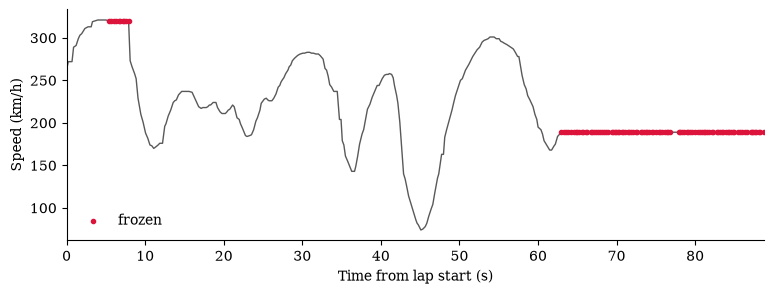

In [6]:
lap = fastest["ANT"]
car = lap.get_car_data()
_, core, _ = freeze_mask(car)
t = (car["SessionTime"] - lap["LapStartTime"]).dt.total_seconds()

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t, car["Speed"], color="0.35", lw=1)
ax.scatter(t[core], car["Speed"][core], s=9, color="crimson", zorder=3, label="frozen")
ax.set(xlabel="Time from lap start (s)", ylabel="Speed (km/h)", xlim=(0, lap["LapTime"].total_seconds()))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
plt.show()

In [7]:
_b = sorted(blocks(car, core, lap["Time"]), key=lambda b: b[3] - b[2], reverse=True)
caption("Figure", "ant", f"ANT's pole lap: car data frozen at {car['Speed'].iloc[_b[0][0]]:.0f} km/h for {_b[0][3] - _b[0][2]:.1f} s"
        + "".join(f", and at {car['Speed'].iloc[b[0]]:.0f} km/h for {b[3] - b[2]:.1f} s" for b in _b[1:3]) + " (red: frozen samples).")

*Figure 1. ANT's pole lap: car data frozen at 189 km/h for 25.8 s, and at 320 km/h for 2.7 s (red: frozen samples).*

### 3.2 Definition check and X/Y confirmation

On the fastest laps: do 104 samples sit inside unchanged runs, and does the frozen Speed disagree with the mean speed implied by X/Y path length over the same window? This follows the approach of comparing an in-car measurement with an independently obtained expected value (Segers, 2014, sec. 3.6 by G. Callea, p. 72). Speed is not reconstructed from X/Y, so agreement cannot rule a freeze out. The same freeze appears in OpenF1 (Appendix A), so it originates upstream of FastF1.

In [8]:
runs, seeds, frozen_pct = [], [], {}
for d, lap in fastest.items():
    car = lap.get_car_data()
    pos = lap.get_pos_data(pad=1, pad_side="both")
    flag, core, run_id = freeze_mask(car)
    frozen_pct[d] = 100 * flag.mean()
    seeds.append(run_id.map(run_id.value_counts())[car["Throttle"] == SENTINEL])
    for i0, i1, t0, t1 in blocks(car, core, lap["Time"]):
        m, dt = xy_path(pos, t0, t1)
        runs.append(dict(Driver=d, Samples=i1 - i0, Duration_s=t1 - t0,
                         FrozenSpeed=car["Speed"].iloc[i0], XYSpeed=3.6 * m / dt if dt > 0 else np.nan))
seeds = pd.concat(seeds)
print(f"Throttle == 104 samples: {len(seeds)}; inside an unchanged run: {(seeds > 1).sum()}; isolated: {(seeds == 1).sum()}\n")

runs = pd.DataFrame(runs).assign(AbsDiff_kmh=lambda x: (x.FrozenSpeed - x.XYSpeed).abs())
runs["Duration"] = pd.cut(runs.Duration_s, [0, 1, 3, np.inf], right=False, labels=["< 1 s", "1-3 s", ">= 3 s"])
print(runs.groupby("Duration", observed=True)["AbsDiff_kmh"].agg(["size", "mean", "max"]).round(1).to_string())

Throttle == 104 samples: 745; inside an unchanged run: 730; isolated: 15

          size  mean    max
Duration                   
< 1 s        2  28.8   51.0
1-3 s       30  21.5   69.7
>= 3 s      29  35.4  139.1


In [9]:
_g = runs.groupby("Duration", observed=True)["AbsDiff_kmh"]
caption("Table", "xy", f"|Frozen Speed − X/Y mean speed| by freeze duration (fastest laps): {(seeds > 1).sum()} of {len(seeds)} sentinel samples "
        f"sit inside unchanged runs; freezes >= 3 s differ by {_g.mean()['>= 3 s']:.0f} km/h on average (max {_g.max()['>= 3 s']:.0f} km/h). "
        "Short freezes span too few position samples for a reliable X/Y mean speed.")

*Table 2. |Frozen Speed − X/Y mean speed| by freeze duration (fastest laps): 730 of 745 sentinel samples sit inside unchanged runs; freezes >= 3 s differ by 35 km/h on average (max 139 km/h). Short freezes span too few position samples for a reliable X/Y mean speed.*

### 3.3 Prevalence on fastest laps

In [10]:
fl = pd.DataFrame({"PU": {d: PU[lap["Team"]] for d, lap in fastest.items()}, "FrozenPct": frozen_pct})
print(fl.groupby("PU")["FrozenPct"].agg(Drivers="size", MeanFrozenPct="mean", MinPct="min", MaxPct="max")
      .round(1).sort_values("MeanFrozenPct", ascending=False).to_string())

               Drivers  MeanFrozenPct  MinPct  MaxPct
PU                                                   
Audi                 2           33.1    30.7    35.5
Mercedes             8           17.5     0.0    40.2
Red Bull Ford        4           10.6     2.9    24.4
Ferrari              6            9.5     0.0    37.6
Honda                2            8.1     4.2    12.1


In [11]:
_m = fl.groupby("PU")["FrozenPct"].mean()
caption("Table", "prev", f"Share of each fastest lap flagged as frozen, by PU: {fl.FrozenPct.min():.0f}–{fl.FrozenPct.max():.0f} % per lap; "
        f"highest PU mean {_m.max():.1f} % ({_m.idxmax()}), lowest {_m.min():.1f} % ({_m.idxmin()}).")

*Table 3. Share of each fastest lap flagged as frozen, by PU: 0–40 % per lap; highest PU mean 33.1 % (Audi), lowest 8.1 % (Honda).*

### 3.4 Simultaneity across cars

Do freezes hit many cars at once (a feed-wide outage) or one car at a time? For every freeze overlapping a driver's laps (whole-session car data), count other cars frozen at its midpoint, against a baseline of random on-track moments (random lap, uniform time within it; seed 0).

In [12]:
fr = []
for d in s.results["Abbreviation"]:
    dl = s.laps.pick_drivers(d)
    car = s.car_data[dl["DriverNumber"].iloc[0]]
    on = list(zip(dl["LapStartTime"].dt.total_seconds(), dl["Time"].dt.total_seconds()))
    fr += [dict(Driver=d, t0=t0, t1=t1) for _, _, t0, t1 in blocks(car, freeze_mask(car)[1], car["SessionTime"].iloc[-1])
           if any(a < t1 and b > t0 for a, b in on)]
fr = pd.DataFrame(fr).assign(Duration_s=lambda x: x.t1 - x.t0)


def others_frozen_at(t, driver):
    return fr[(fr.Driver != driver) & (fr.t0 <= t) & (fr.t1 > t)].Driver.nunique()


fr["OthersAtMid"] = [others_frozen_at((a + b) / 2, d) for d, a, b in zip(fr.Driver, fr.t0, fr.t1)]
rng = np.random.default_rng(0)
lw = s.laps.dropna(subset=["LapStartTime", "Time"])
smp = lw.iloc[rng.integers(0, len(lw), 2000)]
t_rand = smp["LapStartTime"].dt.total_seconds() + rng.random(len(smp)) * (smp["Time"] - smp["LapStartTime"]).dt.total_seconds()
base = pd.Series([others_frozen_at(t, d) for t, d in zip(t_rand, smp["Driver"])])

groups = {"freeze midpoints": fr.OthersAtMid, "freeze midpoints (>= 3 s)": fr.OthersAtMid[fr.Duration_s >= 3],
          "random on-track moments": base}
print(pd.DataFrame({k: {"n": len(v), "mean other cars frozen": v.mean(), ">= 5 other cars": (v >= 5).mean()}
                    for k, v in groups.items()}).T.round(2).to_string())

                                n  mean other cars frozen  >= 5 other cars
freeze midpoints            937.0                    4.33             0.41
freeze midpoints (>= 3 s)   492.0                    4.42             0.44
random on-track moments    2000.0                    3.65             0.31


In [13]:
caption("Table", "sim", f"Other cars frozen at the same instant: {fr.OthersAtMid.mean():.1f} at freeze midpoints vs {base.mean():.1f} at random "
        f"on-track moments, across {len(fr):,} freezes: frequent but only weakly synchronised.")

*Table 4. Other cars frozen at the same instant: 4.3 at freeze midpoints vs 3.6 at random on-track moments, across 937 freezes: frequent but only weakly synchronised.*

### 3.5 Stale-Speed ratio check (diagnostic, not used)

Speed/RPM deviation from each car's per-gear median on all push laps, split by whether Speed repeated the previous sample. If the ratio identified stale Speed, repeated samples would show larger deviations; they do not, so the check is not part of the freeze rule. `STALE_TOL` marks ~99th percentile of |deviation| when Speed changed.

stale
False    [0.007, 0.041, 0.147, 0.347]
True     [0.005, 0.043, 0.157, 0.256]

99th percentile when Speed changed: 0.147; STALE_TOL = 0.15
Repeated-Speed samples beyond STALE_TOL: 54 of 4491


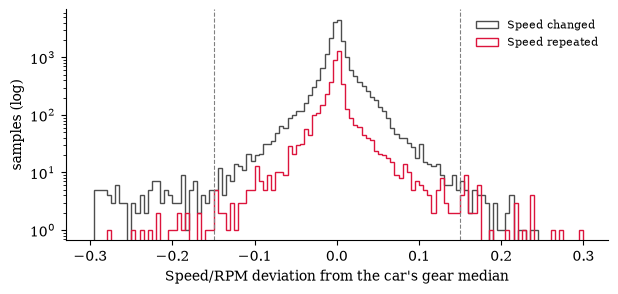

In [14]:
dv = []
for _, lap in s.laps[s.laps["LapTime"].notna()].pick_wo_box().pick_quicklaps().pick_not_deleted().iterlaps():
    car = lap.get_car_data()
    core = freeze_mask(car)[1]
    dv.append(pd.DataFrame({"dev": ratio_dev(car, exclude=core), "stale": car["Speed"].eq(car["Speed"].shift()),
                            "gear": car["nGear"]}).dropna())
dv = pd.concat(dv)
print(dv.groupby("stale")["dev"].apply(lambda x: x.abs().quantile([.5, .9, .99, .999]).round(3).tolist()).rename("|dev| q50/q90/q99/q99.9").to_string())
print(f"\n99th percentile when Speed changed: {dv.loc[~dv.stale, 'dev'].abs().quantile(.99):.3f}; STALE_TOL = {STALE_TOL}")
print(f"Repeated-Speed samples beyond STALE_TOL: {(dv.stale & (dv.dev.abs() > STALE_TOL)).sum()} of {dv.stale.sum()}")

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(-0.3, 0.3, 121)
ax.hist(dv.loc[~dv.stale, "dev"], bins=bins, log=True, histtype="step", color="0.3", label="Speed changed")
ax.hist(dv.loc[dv.stale, "dev"], bins=bins, log=True, histtype="step", color="crimson", label="Speed repeated")
for x in (-STALE_TOL, STALE_TOL):
    ax.axvline(x, color="0.5", ls="--", lw=0.8)
ax.set(xlabel="Speed/RPM deviation from the car's gear median", ylabel="samples (log)")
ax.legend(frameon=False, fontsize=8)
plt.show()

In [15]:
_q = dv.groupby("stale")["dev"].apply(lambda x: x.abs().quantile(0.99))
caption("Figure", "ratio", f"Speed/RPM deviation from each car's gear median (push laps). The 99th percentile of |deviation| is {_q[False]:.3f} "
        f"when Speed changed and {_q[True]:.3f} when it repeated: the ratio does not separate stale Speed, so it is a diagnostic only "
        f"(dashed: ±{STALE_TOL}).")

*Figure 2. Speed/RPM deviation from each car's gear median (push laps). The 99th percentile of |deviation| is 0.147 when Speed changed and 0.157 when it repeated: the ratio does not separate stale Speed, so it is a diagnostic only (dashed: ±0.15).*

### 3.6 Implausible Speed jumps (data-quality finding)

Every single-step Speed increase on push laps that exceeds the power-limited bound (e). They show Speed catching up after it stopped updating; they add noise to individual readings and are reported, not filtered. Position is the distance after the nearest preceding corner (X/Y lap position).

In [16]:
jumps = []
for _, lap in s.laps[s.laps["LapTime"].notna()].pick_wo_box().pick_quicklaps().pick_not_deleted().iterlaps():
    car = lap.get_car_data().add_distance()
    hit = np.flatnonzero(implausible_jumps(car))
    if not len(hit):
        continue
    t = car["SessionTime"].dt.total_seconds()
    run = car["Speed"].ne(car["Speed"].shift()).cumsum()
    xyd, pt, cpos = lap_geometry(lap, corners)
    for i, pos in zip(hit, position_at(xyd, pt, car["SessionTime"].iloc[hit])):
        sp0, sp1, dt = car["Speed"].iloc[i - 1], car["Speed"].iloc[i], t.iloc[i] - t.iloc[i - 1]
        prev = run == run.iloc[i - 1]  # run of unchanged Speed before the jump
        passed = {n: x for n, x in cpos.items() if x <= pos}
        jumps.append(dict(Driver=lap["Driver"], LapNumber=int(lap["LapNumber"]), From=sp0, To=sp1, a=(sp1 - sp0) / 3.6 / dt,
                          bound=ACC_POWER_W / (ACC_MASS_KG * sp0 / 3.6), StaleBefore_s=t.iloc[i] - t[prev].iloc[0],
                          Has104=bool((car["Throttle"][prev] == SENTINEL).any()), Throttle=car["Throttle"].iloc[i],
                          AfterCorner=f"T{max(passed, key=passed.get)}" if passed else "-",
                          AfterCorner_m=pos - max(passed.values()) if passed else np.nan))
jumps = pd.DataFrame(jumps)
print(f"Implausible jumps: {len(jumps)} on {jumps.groupby(['Driver', 'LapNumber']).ngroups} push laps; "
      f"median a / bound {(jumps.a / jumps.bound).median():.2f}; inside a 104 run: {jumps.Has104.sum()}")
summary = {
    "speed before (km/h)": pd.cut(jumps.From, [0, 150, 200, 250, 300, 400]),
    "unchanged Speed before (s)": pd.cut(jumps.StaleBefore_s, [0, 0.3, 0.5, 1, 100]),
    "distance after preceding corner (m)": pd.cut(jumps.AfterCorner_m, [0, 150, 300, 600, 10000]),
}
for name, x in summary.items():
    print(f"\n{name}:\n" + x.value_counts().sort_index().to_string())
print(f"\nWithin 300 m after a corner: {(jumps.AfterCorner_m <= 300).mean():.0%}; at full throttle (>= 98): {(jumps.Throttle >= FULL_THROTTLE).mean():.0%}")
print("Most frequent preceding corners:", jumps.AfterCorner.value_counts().head(5).to_dict())

Implausible jumps: 291 on 103 push laps; median a / bound 1.41; inside a 104 run: 78

speed before (km/h):
From
(0, 150]       17
(150, 200]    125
(200, 250]     93
(250, 300]     47
(300, 400]      9

unchanged Speed before (s):
StaleBefore_s
(0.0, 0.3]       47
(0.3, 0.5]       50
(0.5, 1.0]       77
(1.0, 100.0]    117

distance after preceding corner (m):
AfterCorner_m
(0, 150]        176
(150, 300]       37
(300, 600]       16
(600, 10000]     11

Within 300 m after a corner: 77%; at full throttle (>= 98): 93%
Most frequent preceding corners: {'T18': 76, 'T17': 51, 'T14': 43, '-': 41, 'T9': 27}


In [17]:
caption("Table", "jumps", f"Implausible Speed jumps on push laps: {len(jumps)} on {jumps.groupby(['Driver', 'LapNumber']).ngroups} laps "
        f"(bound {ACC_POWER_W / (ACC_MASS_KG * 305 / 3.6):.1f} m/s² at 305 km/h); {(jumps.AfterCorner_m <= 300).mean():.0%} within 300 m after a corner, "
        f"{jumps.Has104.sum()} inside a 104 run, median a / bound {(jumps.a / jumps.bound).median():.2f}. Reported, not filtered.")

*Table 5. Implausible Speed jumps on push laps: 291 on 103 laps (bound 13.5 m/s² at 305 km/h); 77% within 300 m after a corner, 78 inside a 104 run, median a / bound 1.41. Reported, not filtered.*

## 4. Push-lap selection and coverage

Few fastest laps are clean through 130R (table below). Frozen share varies from lap to lap, so each driver's best clean push lap is used instead. **Push lap:** timed, `pick_wo_box()` (no in/out laps), `pick_quicklaps()` (≤ 107 % of session best; removes cool-down and aborted laps), `pick_not_deleted()`, and channels not dead or missing (`dead_lap_reason`: Speed zero for the whole lap, X/Y (0, 0) on any sample, or X/Y stationary for the whole lap). **Clean through a window:** no flagged freeze overlaps the time between passing the two corners (position sample nearest each corner's X/Y). **Selection, per driver per window:** latest quali part with a clean lap, then fastest lap within it; `QualiPart` is kept with every selection.

In [18]:
def clean_through(lap, corners, window=WINDOW_130R):
    """True if no flagged freeze overlaps the time between the two corners of `window`."""
    ta, tb = sorted(corner_times(lap, window, corners))
    return not frozen_between(lap, lap.get_car_data(), ta, tb)


push, lap_log = push_laps(s)
timed = s.laps[s.laps["LapTime"].notna()]
qc = pd.DataFrame([dict(Driver=lap["Driver"], LapNumber=int(lap["LapNumber"]), Push=i in push.index,
                        FrozenPct=100 * freeze_mask(lap.get_car_data())[0].mean(), Clean130R=clean_through(lap, corners))
                   for i, lap in timed.iterlaps()], index=timed.index)
clean130 = qc.loc[push.index, "Clean130R"]
sel130 = best_clean_lap(push[clean130])
pq = qc[qc.Push].groupby("Driver")["FrozenPct"]
print(f"Push laps: {len(push)} of {len(timed)} timed; drivers with both a freeze-free and a frozen push lap: "
      f"{((pq.min() == 0) & (pq.max() > 0)).sum()} / {pq.ngroups}\n")
cov = pd.DataFrame({"Drivers": pd.Series({d: PU[l["Team"]] for d, l in fastest.items()}).value_counts(),
                    "Clean fastest lap": pd.Series({d: PU[l["Team"]] for d, l in fastest.items() if qc.loc[l.name, "Clean130R"]}).value_counts(),
                    "Clean push lap selected": sel130["Team"].map(PU).value_counts()}).fillna(0).astype(int)
cov.loc["Total"] = cov.sum()
print(cov.to_string())

Push laps: 108 of 227 timed; drivers with both a freeze-free and a frozen push lap: 16 / 22

               Drivers  Clean fastest lap  Clean push lap selected
Audi                 2                  0                        2
Ferrari              6                  2                        5
Honda                2                  1                        2
Mercedes             8                  3                        8
Red Bull Ford        4                  2                        4
Total               22                  8                       21


In [19]:
_n = len(fastest)
caption("Table", "cov130", f"Drivers with clean data through 130R (T14–T16), by PU: {cov.loc['Total', 'Clean fastest lap']} of {_n} using fastest laps, "
        f"{cov.loc['Total', 'Clean push lap selected']} of {_n} using the best clean push lap; none for {', '.join(sorted(set(fastest) - set(sel130.Driver))) or 'nobody'}.")

*Table 6. Drivers with clean data through 130R (T14–T16), by PU: 8 of 22 using fastest laps, 21 of 22 using the best clean push lap; none for OCO.*

In [20]:
order = [d for d in s.results["Abbreviation"] if d in set(sel130["Driver"])]
print(sel130.assign(PU=sel130["Team"].map(PU), LapTime_s=sel130["LapTime"].dt.total_seconds())
      .set_index("Driver").loc[order, ["PU", "QualiPart", "LapNumber", "LapTime_s"]].to_string())

                   PU QualiPart  LapNumber  LapTime_s
Driver                                               
ANT          Mercedes        Q3       14.0     88.839
RUS          Mercedes        Q3       17.0     89.076
PIA          Mercedes        Q3       16.0     89.132
LEC           Ferrari        Q3       17.0     89.405
NOR          Mercedes        Q3       16.0     89.409
HAM           Ferrari        Q3       16.0     89.567
GAS          Mercedes        Q1        2.0     90.765
HAD     Red Bull Ford        Q3       14.0     89.978
BOR              Audi        Q3       16.0     90.648
LIN     Red Bull Ford        Q2       11.0     90.694
VER     Red Bull Ford        Q2       11.0     90.262
HUL              Audi        Q1        4.0     90.542
LAW     Red Bull Ford        Q1        8.0     90.657
COL          Mercedes        Q1        2.0     91.458
SAI          Mercedes        Q1        5.0     91.676
ALB          Mercedes        Q1        5.0     91.510
BEA           Ferrari       

In [21]:
_q = sel130.QualiPart.value_counts()
caption("Table", "sel130", "Lap selected per driver for 130R: " + ", ".join(f"{_q.get(k, 0)} from {k}" for k in ["Q3", "Q2", "Q1"])
        + "; `QualiPart` travels with every measurement.")

*Table 7. Lap selected per driver for 130R: 8 from Q3, 2 from Q2, 11 from Q1; `QualiPart` travels with every measurement.*

## 5. Exclusion log

Every timed lap not used for 130R, with the reason. Deleted laps are excluded: Japan's one deleted lap (track limits at T13, Spoon) affects exit speed onto the back straight, which feeds the measured straight to 130R.

In [22]:
excl = pd.concat([
    lap_log.assign(Scope="lap"),
    push.loc[~clean130, ["Driver", "LapNumber", "QualiPart"]].assign(Scope="130R", Reason="freeze overlaps T14-T16"),
    push.loc[clean130 & ~push.index.isin(sel130.index), ["Driver", "LapNumber", "QualiPart"]]
        .assign(Scope="130R", Reason="clean, not selected (earlier part or slower)"),
])
print(excl.groupby(["Scope", "Reason"]).size().rename("laps").to_string())
print("\nNo clean lap through 130R:", sorted(set(fastest) - set(sel130["Driver"])))

Scope  Reason                                      
130R   clean, not selected (earlier part or slower)    36
       freeze overlaps T14-T16                         51
lap    deleted: TRACK LIMITS AT TURN 13 LAP 18          1
       in/out lap                                      99
       slower than 107 % (cool-down/aborted)           19

No clean lap through 130R: ['OCO']


In [23]:
caption("Table", "excl", f"Exclusions: of {len(timed)} timed laps, {len(lap_log)} fail the push-lap filter; of the {len(push)} push laps, "
        f"{(~clean130).sum()} have a freeze in T14–T16, {(clean130 & ~push.index.isin(sel130.index)).sum()} are clean but not selected, "
        f"and {len(sel130)} are used.")

*Table 8. Exclusions: of 227 timed laps, 119 fail the push-lap filter; of the 108 push laps, 51 have a freeze in T14–T16, 36 are clean but not selected, and 21 are used.*

## 6. Sector PKE and full-throttle segments

**A. Sectors** (partial replication of Bopaiah & Samuel, 2021, pp. 4-5; coverage is limited by freezes): each push lap is split into the three FIA sectors with FastF1 sector timestamps (`LapStartTime`, `Sector1SessionTime`, `Sector2SessionTime`, `Sector3SessionTime`), and PKE is computed per sector and for the full lap with their eq. 4. **B. Straights** (our refinement): full-throttle segments (Throttle >= 98, Brake off, single-sample dips merged, >= 500 m), labelled by the corner they end at (X/Y), with clipping metrics and the C5.2.8 taper power at peak speed. Sectors and segments that overlap a freeze are dropped and logged, as are segments whose peak is their first sample (start truncated); each driver's best clean lap is then used per sector or straight (latest quali part first, then fastest). Distances are car-data distances within the interval. Comparisons within a straight are unaffected by its gradient, which is the same for all cars; comparisons across straights are not.

### 6.1 Computation

In [24]:
sec_all, seg_all = sector_segment_rows(push, corners)
ms_all = main_straight_rows(s, push)
sectors, straights, main_straight, segments = select_clean(sec_all, seg_all, ms_all)

seg_log = seg_all.assign(Reason=segment_reason(seg_all)).query("Reason != ''")
print(f"Sectors: {len(sec_all)} computed, {sec_all.Frozen.sum()} dropped (freeze), {len(sectors)} selected")
print(f"Segments: {len(seg_all)} detected, {len(seg_log)} dropped, {len(straights)} selected")
print("\nDropped segments by label:\n" + seg_log.groupby(["Label", "Reason"]).size().rename("n").to_string())
missing = {k: sorted(set(fastest) - set(sectors.loc[sectors.Sector == k, "Driver"])) for k in SECTORS}
print("\nDrivers with no clean sector:", {k: v for k, v in missing.items() if v})

Sectors: 432 computed, 241 dropped (freeze), 75 selected
Segments: 313 detected, 165 dropped, 43 selected

Dropped segments by label:
Label  Reason                   
T1     overlaps freeze              17
       truncated by lap boundary    73
T10    overlaps freeze               1
T13    overlaps freeze               8
T16    overlaps freeze              48
T18    overlaps freeze               1
T2     overlaps freeze               3
       truncated by lap boundary    11
T4     overlaps freeze               1
T5     overlaps freeze               1
T9     overlaps freeze               1

Drivers with no clean sector: {'S2': ['BOT', 'OCO'], 'S3': ['ALO', 'BEA', 'BOT', 'OCO', 'STR'], 'Full': ['ALO', 'BEA', 'BOT', 'GAS', 'OCO', 'STR']}


### 6.2 Team-to-PU mapping

In [25]:
print(s.results[["TeamName"]].drop_duplicates().assign(PU=lambda x: x.TeamName.map(PU)).to_string(index=False))

       TeamName            PU
       Mercedes      Mercedes
        McLaren      Mercedes
        Ferrari       Ferrari
         Alpine      Mercedes
Red Bull Racing Red Bull Ford
           Audi          Audi
   Racing Bulls Red Bull Ford
   Haas F1 Team       Ferrari
       Williams      Mercedes
       Cadillac       Ferrari
   Aston Martin         Honda


In [26]:
caption("Table", "pu", 'Team-to-PU mapping applied to every row, verified against The Race, "What engine every F1 team is using for 2026 rules".')

*Table 9. Team-to-PU mapping applied to every row, verified against The Race, "What engine every F1 team is using for 2026 rules".*

### 6.3 Sanity checks

In [27]:
print("Full-throttle segments per push lap:", seg_all.groupby(["Driver", "LapNumber"]).size().value_counts().sort_index().to_dict(), "\n")
print(straights.groupby("Label").agg(Drivers=("Driver", "size"), Via=("Via", lambda x: x.mode().iat[0]),
                                    StartPos_m=("StartPos_m", "median"), EndPos_m=("EndPos_m", "median"),
                                    EndPos_IQR_m=("EndPos_m", lambda x: x.quantile(.75) - x.quantile(.25)),
                                    Length_m=("length_m", "median"))
      .sort_values("EndPos_m").round(0).to_string())

Full-throttle segments per push lap: {2: 10, 3: 95, 4: 2} 

       Drivers  Via  StartPos_m  EndPos_m  EndPos_IQR_m  Length_m
Label                                                            
T13         22  T12      2966.0    3685.0          44.0     719.0
T16         21  T15      4029.0    5232.0          12.0    1209.0


In [28]:
_s = straights[straights.Label.isin(["T13", "T16"])]
_iqr = _s.groupby("Label").EndPos_m.apply(lambda x: x.quantile(.75) - x.quantile(.25)).max()
caption("Table", "labels", "Segment labels: " + "; ".join(
    f"straight ending {k} ({g.Driver.nunique()} drivers{', none for ' + ', '.join(sorted(set(fastest) - set(g.Driver))) if set(fastest) - set(g.Driver) else ''})"
    for k, g in _s.groupby("Label")) + f"; segment end positions agree across drivers within {_iqr:.0f} m (IQR).")

*Table 10. Segment labels: straight ending T13 (22 drivers); straight ending T16 (21 drivers, none for OCO); segment end positions agree across drivers within 44 m (IQR).*

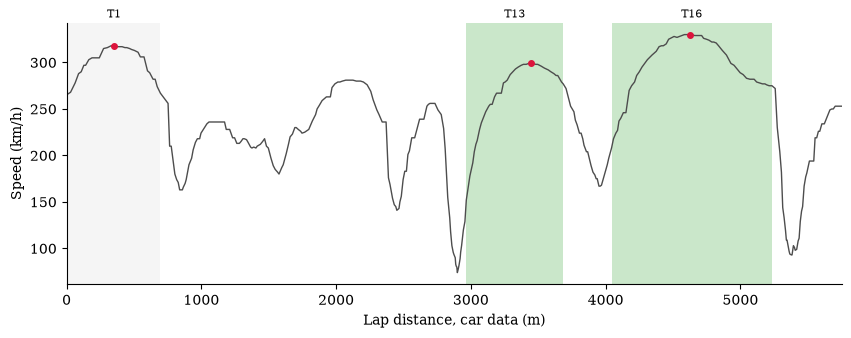

RUS lap 14 (Q2)


In [29]:
drv = "RUS" if ((sectors.Driver == "RUS") & (sectors.Sector == "Full")).any() else sectors.loc[sectors.Sector == "Full", "Driver"].iat[0]
lapno = sectors.loc[(sectors.Driver == drv) & (sectors.Sector == "Full"), "LapNumber"].iat[0]
lap = push[(push.Driver == drv) & (push.LapNumber == lapno)].iloc[0]
car = lap.get_car_data().add_distance()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(car["Distance"], car["Speed"], color="0.3", lw=1)
for _, g in seg_all[(seg_all.Driver == drv) & (seg_all.LapNumber == lapno)].iterrows():
    ax.axvspan(g.start_m, g.end_m, color="0.85" if g.Truncated else "tab:green", alpha=0.25, lw=0)
    ax.plot(g.peak_m, g.peak_speed, "o", color="crimson", ms=4)
    ax.text((g.start_m + g.end_m) / 2, 1.02, g.Label, transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
ax.set(xlabel="Lap distance, car data (m)", ylabel="Speed (km/h)", xlim=(0, car["Distance"].iloc[-1]))
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"{drv} lap {lapno} ({lap['QualiPart']})")

In [30]:
caption("Figure", "lapplot", f"{drv} lap {lapno} ({lap['QualiPart']}), a freeze-free full lap: green = full-throttle segments with peak speed (red); "
        "grey = segment cut by the start/finish line (measured separately as the main straight).")

*Figure 3. RUS lap 14 (Q2), a freeze-free full lap: green = full-throttle segments with peak speed (red); grey = segment cut by the start/finish line (measured separately as the main straight).*

In [31]:
print(straights.groupby("Label")[["peak_speed", "end_speed", "clip_delta", "clip_distance", "decel_rate", "vmax_position", "taper_kw_at_peak"]]
      .mean().round(1).sort_values("clip_delta", ascending=False).to_string())

       peak_speed  end_speed  clip_delta  clip_distance  decel_rate  vmax_position  taper_kw_at_peak
Label                                                                                               
T16         328.0      272.2        55.8          607.2         9.2            0.5             159.8
T13         293.4      270.5        22.9          248.2         9.0            0.7             329.8


In [32]:
caption("Table", "metrics", "Mean clipping metrics per straight: " + "; ".join(
    f"ending {k}: clip_delta {g.clip_delta.mean():.1f} km/h after a {g.peak_speed.mean():.1f} km/h peak, vmax_position mean "
    f"{g.vmax_position.mean():.2f} (median {g.vmax_position.median():.2f}, n = {len(g)})" for k, g in straights[straights.Label.isin(["T13", "T16"])].groupby("Label")) + ".")

*Table 11. Mean clipping metrics per straight: ending T13: clip_delta 22.9 km/h after a 293.4 km/h peak, vmax_position mean 0.65 (median 0.65, n = 22); ending T16: clip_delta 55.8 km/h after a 328.0 km/h peak, vmax_position mean 0.50 (median 0.51, n = 21).*

### 6.4 Main straight (crosses timing line)

The start/finish line splits the main straight between two laps, so it is measured on the car data around each push lap's start (±30 s, whole-session car data): the full-throttle segment containing the line, with both sides (end of the previous lap, start of the push lap) freeze-free. These rows are flagged `CrossesTimingLine`: energy is accounted per lap at the timing line (FIA 2026 Tech Regs C5.2.2), so the segment spans two energy laps. Distances are relative to the timing line. Reported separately from the other straights.

In [33]:
print(ms_all.Status.value_counts().to_string())
print(f"\nMain straight selected for {len(main_straight)} / {len(fastest)} drivers\n")
print(main_straight[["Driver", "PU", "QualiPart", "start_m", "end_m", "peak_speed", "end_speed", "clip_delta", "clip_distance", "decel_rate"]]
      .set_index("Driver").reindex([d for d in fastest if d in set(main_straight.Driver)]).round(1).to_string())

Status
overlaps freeze                             54
ok                                          53
no full-throttle segment across the line     1

Main straight selected for 19 / 22 drivers

                   PU QualiPart  start_m  end_m  peak_speed  end_speed  clip_delta  clip_distance  decel_rate
Driver                                                                                                       
ANT          Mercedes        Q2    -79.6  713.6       313.0      260.0        53.0          376.4        14.1
RUS          Mercedes        Q2    -95.2  695.9       318.0      267.0        51.0          347.7        14.7
PIA          Mercedes        Q3   -138.6  665.2       326.0      283.0        43.0          300.1        14.3
LEC           Ferrari        Q3   -124.8  638.6       330.0      297.0        33.0          219.2        15.1
NOR          Mercedes        Q3   -109.9  674.6       321.0      271.0        50.0          333.3        15.0
HAM           Ferrari        Q3   -11

In [34]:
_ms = main_straight
caption("Table", "main", f"Main straight (crosses the timing line), {len(_ms)} of {len(fastest)} drivers"
        f"{' (no clean crossing for ' + ', '.join(sorted(set(fastest) - set(_ms.Driver))) + ')' if set(fastest) - set(_ms.Driver) else ''}: segments start "
        f"{-_ms.start_m.max():.0f}–{-_ms.start_m.min():.0f} m before the line; clip_delta {_ms.clip_delta.min():.0f} km/h "
        f"({_ms.loc[_ms.clip_delta.idxmin(), 'Driver']}) to {_ms.clip_delta.max():.0f} km/h ({_ms.loc[_ms.clip_delta.idxmax(), 'Driver']}).")

*Table 12. Main straight (crosses the timing line), 19 of 22 drivers (no clean crossing for ALO, BOT, STR): segments start 80–173 m before the line; clip_delta 10 km/h (BOR) to 59 km/h (OCO).*

In [35]:
print(sectors.pivot(index="Driver", columns="Sector", values="PKE").reindex(list(fastest))[["S1", "S2", "S3", "Full"]].round(2).to_string())

Sector    S1    S2    S3  Full
Driver                        
ANT     3.87  6.53  4.53  5.10
RUS     4.14  6.57  4.53  5.15
PIA     3.99  6.44  4.73  5.14
LEC     3.95  6.07  4.75  4.98
NOR     3.62  6.40  4.70  5.00
HAM     3.73  5.93  4.74  4.86
GAS     4.39  6.48  4.77   NaN
HAD     4.03  6.64  4.70  5.32
BOR     4.05  6.43  4.51  5.16
LIN     3.80  6.74  4.54  5.20
VER     4.08  6.55  4.72  5.19
OCO     4.09   NaN   NaN   NaN
HUL     3.93  6.54  4.94  5.37
LAW     3.79  6.90  4.71  5.26
COL     4.53  6.49  4.96  5.41
SAI     4.06  6.66  4.73  5.43
ALB     4.17  6.63  4.65  5.21
BEA     3.84  6.30   NaN   NaN
PER     4.27  6.55  4.18  5.20
BOT     4.22   NaN   NaN   NaN
ALO     5.49  6.03   NaN   NaN
STR     3.70  5.90   NaN   NaN


In [36]:
_pv = sectors.pivot(index="Driver", columns="Sector", values="PKE")
_s2 = _pv.dropna(subset=["S2"])
caption("Table", "pke", "PKE per sector and full lap (m/s², best clean lap per driver and sector). Coverage: "
        + ", ".join(f"{k} {_pv[k].notna().sum()}" for k in ["S1", "S2", "S3", "Full"]) + f" of {len(fastest)} drivers. S2 is the highest sector for "
        f"{(_s2.S2 >= _s2[['S1', 'S3']].max(axis=1)).sum()} of {len(_s2)} drivers with an S2 value.")

*Table 13. PKE per sector and full lap (m/s², best clean lap per driver and sector). Coverage: S1 22, S2 20, S3 17, Full 16 of 22 drivers. S2 is the highest sector for 20 of 20 drivers with an S2 value.*

### 6.5 Output

In [37]:
Path("data").mkdir(exist_ok=True)
to_seconds(sectors).to_csv("data/japan_sectors.csv", index=False)
to_seconds(segments).to_csv("data/japan_segments.csv", index=False)
print(f"data/japan_sectors.csv: {len(sectors)} rows; data/japan_segments.csv: {len(segments)} rows")

data/japan_sectors.csv: 75 rows; data/japan_segments.csv: 62 rows


## 7. Validation 2: speed loss at 130R

130R (T15) is a flat-out corner inside the T14-T16 full-throttle segment, not the segment end. Pre-specified definition (primary), matching F1Technical's "minimum speed recorded at 130R": peak speed before T15, then minimum speed from that peak to T15 + 100 m (X/Y lap position). Sensitivity: minimum from the peak to the segment end. The segment-end window ends at the last full-throttle sample before the driver lifts or brakes for T16. Segers (2014, p. 52) describes the end of a straight as where top speed is reached just before braking; The Race ("Why key 2026 F1 rules fix will create another problem", 20 Apr 2026) reports that Vmax should peak late on a straight but with 2026 cars peaks earlier and gradually declines; our observed `vmax_position` per straight is in the mean-metrics table of Section 6.3. clip_delta measures the full-throttle speed lost between the peak and that point. Which window is closer to F1Technical is reported below. Both are computed on our cleaned laps (selected T16 segment) and, as a check, on each driver's raw fastest lap (`pick_fastest`, no freeze mask, no push-lap selection), averaged per team. F1Technical does not state its data source, the driver or lap per team, or the exact minimum-speed location; if it uses the same public timing feed it may contain the same freezes. It is an approximate reference, not ground truth.

In [38]:
F1T_130R = {  # F1Technical, "F1MATHS ... superclipping ... Suzuka" (f1technical.net/news/28392): (peak, minimum) km/h
    "Audi": (329, 278), "Aston Martin": (327, 267), "Red Bull Racing": (330, 274),
    "Racing Bulls": (333, 276), "Alpine": (333, 278), "Mercedes": (329, 271),  # Mercedes listed as "53 km/h" in source
}


def speed_130r(lap):
    """On the full-throttle segment containing T15: peak speed before T15, minimum from that peak to T15 + 100 m
    (primary) and to the segment end (sensitivity), and whether a freeze overlaps T14-T16. No freeze filtering."""
    car = lap.get_car_data().add_distance()
    xyd, pt, cpos = lap_geometry(lap, corners)
    frozen = frozen_between(lap, car, *sorted(corner_times(lap, (14, 16), corners)))
    for a, b in full_throttle_segments(car, lap["Time"]):
        p0, p1 = position_at(xyd, pt, car["SessionTime"].iloc[[a, b - 1]])
        if p0 < cpos[15] < p1:
            break
    else:
        return dict(Peak=np.nan, Min100=np.nan, MinEnd=np.nan, FrozenT14_T16=frozen)
    seg = car.iloc[a:b]
    lp, sp = position_at(xyd, pt, seg["SessionTime"]), seg["Speed"].to_numpy()
    before = np.flatnonzero(lp <= cpos[15])
    k = before[sp[before] == sp[before].max()][-1]  # last sample at peak before T15
    return dict(Peak=sp[k], Min100=sp[k:][lp[k:] <= cpos[15] + 100].min(), MinEnd=sp[k:].min(), FrozenT14_T16=frozen)


RAW_130R = pd.DataFrame({d: speed_130r(l) for d, l in fastest.items()}).T  # raw fastest laps, computed once


def validation2(segs):
    """Team table (raw fastest laps, cleaned laps from `segs`, F1Technical) and mean absolute differences."""
    clean_laps = {r.Driver: push[(push.Driver == r.Driver) & (push.LapNumber == r.LapNumber)].iloc[0]
                  for r in segs[(segs.Label == "T16") & ~segs.CrossesTimingLine].itertuples()}
    v2 = pd.concat({"Raw": RAW_130R, "Clean": pd.DataFrame({d: speed_130r(l) for d, l in clean_laps.items()}).T},
                   names=["Set", "Driver"])
    v2["Team"] = [fastest[d]["Team"] for d in v2.index.get_level_values("Driver")]
    team = v2.groupby(["Set", "Team"])[["Peak", "Min100", "MinEnd"]].mean().unstack("Set")
    team.columns = [f"{s}_{m}" for m, s in team.columns]
    cmp = pd.DataFrame(F1T_130R, index=["F1T_Peak", "F1T_Min"]).T.join(team)
    cmp["Raw_frozen"] = v2.loc["Raw"].groupby("Team")["FrozenT14_T16"].agg(lambda x: f"{int(x.sum())}/{len(x)}")
    for src in ["Raw", "Clean"]:
        for w in ["Min100", "MinEnd"]:
            cmp[f"{src}_Drop_{w}"] = cmp[f"{src}_Peak"] - cmp[f"{src}_{w}"]
    cmp["F1T_Drop"] = cmp.F1T_Peak - cmp.F1T_Min
    mad = pd.DataFrame({(src, w): {"Peak": (cmp[f"{src}_Peak"] - cmp.F1T_Peak).abs().mean(),
                                   "Min": (cmp[f"{src}_{w}"] - cmp.F1T_Min).abs().mean(),
                                   "Drop": (cmp[f"{src}_Drop_{w}"] - cmp.F1T_Drop).abs().mean(),
                                   "Teams": cmp[f"{src}_{w}"].notna().sum()}
                        for src in ["Raw", "Clean"] for w in ["Min100", "MinEnd"]}).T
    mad.index.names = ["Set", "Window"]
    return cmp, mad


V2_COLS = ["F1T_Peak", "Raw_Peak", "Clean_Peak", "F1T_Min", "Raw_Min100", "Clean_Min100", "Raw_MinEnd", "Clean_MinEnd",
           "F1T_Drop", "Raw_Drop_Min100", "Clean_Drop_Min100", "Raw_Drop_MinEnd", "Clean_Drop_MinEnd", "Raw_frozen"]
cmp, mad = validation2(segments)
print(cmp[V2_COLS].round(1).to_string(), "\n")
print("Mean absolute difference from F1Technical (km/h; teams with a value):")
print(mad.round(1).to_string())

                 F1T_Peak Raw_Peak Clean_Peak  F1T_Min Raw_Min100 Clean_Min100 Raw_MinEnd Clean_MinEnd  F1T_Drop Raw_Drop_Min100 Clean_Drop_Min100 Raw_Drop_MinEnd Clean_Drop_MinEnd Raw_frozen
Audi                  329    299.0      331.0      278      291.0        286.0      290.0        276.0        51             8.0              45.0             9.0              55.0        2/2
Aston Martin          327    318.5      322.0      267      281.0        277.5      263.5        260.0        60            37.5              44.5            55.0              62.0        1/2
Red Bull Racing       330    329.0      329.0      274      287.5        287.5      273.5        273.5        56            41.5              41.5            55.5              55.5        0/2
Racing Bulls          333    320.0      334.0      276      289.5        290.0      280.0        278.0        57            30.5              44.0            40.0              56.0        2/2
Alpine                333    311.0      

In [39]:
_dd = cmp.F1T_Drop - cmp.Clean_Drop_Min100
_raw = cmp.Raw_frozen.str.split("/", expand=True).astype(int).sum()
caption("Table", "v2", f"130R peak, minimum and drop per team (km/h): raw fastest laps, our cleaned laps, F1Technical. Primary window, cleaned laps: "
        f"peak speeds within {(cmp.Clean_Peak - cmp.F1T_Peak).abs().max():.1f} km/h of F1Technical; drops {_dd.min():.1f}–{_dd.max():.1f} km/h smaller. "
        f"Smallest/largest drop: F1Technical {cmp.F1T_Drop.idxmin()}/{cmp.F1T_Drop.idxmax()}, ours {cmp.Clean_Drop_Min100.idxmin()}/{cmp.Clean_Drop_Min100.idxmax()}. "
        f"Raw fastest laps: {_raw[0]} of {_raw[1]} have a freeze in T14–T16"
        + (f"; no value for {', '.join(cmp.index[cmp.Raw_Peak.isna()])}" if cmp.Raw_Peak.isna().any() else "") + ". "
        "Mean absolute drop difference: " + "; ".join(f"{s} laps, {w}: {mad.loc[(s, w), 'Drop']:.1f} km/h ({int(mad.loc[(s, w), 'Teams'])} teams)"
                                                      for s in ["Raw", "Clean"] for w in ["Min100", "MinEnd"]) + ".")

*Table 14. 130R peak, minimum and drop per team (km/h): raw fastest laps, our cleaned laps, F1Technical. Primary window, cleaned laps: peak speeds within 5.0 km/h of F1Technical; drops 6.0–15.5 km/h smaller. Smallest/largest drop: F1Technical Audi/Aston Martin, ours Red Bull Racing/Alpine. Raw fastest laps: 8 of 12 have a freeze in T14–T16. Mean absolute drop difference: Raw laps, Min100: 25.2 km/h (6 teams); Raw laps, MinEnd: 15.2 km/h (6 teams); Clean laps, Min100: 11.6 km/h (6 teams); Clean laps, MinEnd: 2.5 km/h (6 teams).*

## 8. Teammate and same-PU comparisons

Following Bopaiah & Samuel (2021, pp. 4-5): **STDD** (same team, different driver) and **SPDT** (same PU, different team). Unlike the paper, values stay continuous: no normalisation to the best driver and no Low/High modes. Per straight (T13; T16 via 130R; the main straight separately, as it crosses the timing line) on clip_delta, decel_rate, peak_speed and segment PKE, and per sector on PKE. Every row carries coverage (n drivers) and the quali part of each lap. STDD: driver A is the better-qualified teammate, Δ = A − B. SPDT: each team's mean, then the PU mean over its drivers and the range of its team means. One or two cars per team, one lap each: these are descriptions, not estimates of team or PU effects.

In [40]:
METRICS = {"clip_delta": "clip", "decel_rate": "decel", "peak_speed": "peak", "pke": "PKE"}
RANK = {d: i for i, d in enumerate(fastest)}  # qualifying classification
def straight_tables(segs):
    """The three measured straights from a combined segments table."""
    return {"T12→T13": segs[(segs.Label == "T13") & ~segs.CrossesTimingLine],
            "T14→T16 via 130R": segs[(segs.Label == "T16") & ~segs.CrossesTimingLine],
            "Main straight (crosses timing line)": segs[segs.CrossesTimingLine]}


STRAIGHTS = straight_tables(segments)


def stdd(df, metrics):
    """Teammates side by side: A = better-qualified driver, B = teammate, Δ = A − B."""
    rows = []
    for team, g in df.assign(rank=df.Driver.map(RANK)).sort_values("rank").groupby("Team", sort=False):
        a, b = g.iloc[0], (g.iloc[1] if len(g) > 1 else None)
        r = dict(Team=team, PU=a.PU, n=len(g), A=a.Driver, A_part=a.QualiPart,
                 B=b.Driver if b is not None else "-", B_part=b.QualiPart if b is not None else "-")
        for m, short in metrics.items():
            r[f"{short}_A"], r[f"{short}_B"] = a[m], (b[m] if b is not None else np.nan)
            r[f"Δ{short}"] = r[f"{short}_A"] - r[f"{short}_B"]
        rows.append(r)
    return pd.DataFrame(rows).sort_values(["PU", "Team"]).set_index("Team")


def spdt(df, metrics):
    """Per PU: each team's mean (n, quali parts), then the PU mean over drivers and the range of team means."""
    df = df.assign(rank=df.Driver.map(RANK)).sort_values("rank").rename(columns=metrics)
    cols = list(metrics.values())
    out = []
    for pu, d in df.groupby("PU"):
        team = d.groupby("Team").agg(n=("Driver", "size"), parts=("QualiPart", "/".join), **{c: (c, "mean") for c in cols})
        team.index = pd.MultiIndex.from_product([[pu], team.index])
        summary = pd.DataFrame([dict(n=len(d), parts="", **d[cols].mean()),
                                dict(n=len(team), parts="", **(team[cols].max() - team[cols].min()))],
                               index=pd.MultiIndex.from_tuples([(pu, "PU mean (drivers)"), (pu, "range (team means)")]))
        out += [team, summary]
    return pd.concat(out)


def comparison_summary(tables):
    """Per straight: n drivers, STDD mean/max |Δclip_delta| over teammate pairs, SPDT range of team means per PU."""
    rows = {}
    for name, df in tables.items():
        d = stdd(df, {"clip_delta": "clip"})["Δclip"].abs()
        rng = df.groupby(["PU", "Team"]).clip_delta.mean().groupby("PU").agg(lambda x: x.max() - x.min() if len(x) > 1 else np.nan)
        rows[name] = {"drivers": len(df), "STDD pairs": int(d.notna().sum()), "STDD mean |Δclip|": d.mean(),
                      "STDD max |Δclip|": d.max(), **{f"SPDT range {pu}": v for pu, v in rng.items()}}
    return pd.DataFrame(rows).T


for name, df in STRAIGHTS.items():
    print(f"=== STDD: {name} (n = {len(df)} drivers)")
    print(stdd(df, METRICS).round(1).to_string(), "\n")

=== STDD: T12→T13 (n = 22 drivers)
                            PU  n    A A_part    B B_part  clip_A  clip_B  Δclip  decel_A  decel_B  Δdecel  peak_A  peak_B  Δpeak  PKE_A  PKE_B  ΔPKE
Team                                                                                                                                                 
Audi                      Audi  2  BOR     Q3  HUL     Q2    19.0    21.0   -2.0      7.5      7.5    -0.1   290.0   290.0    0.0    6.7    6.6   0.1
Cadillac               Ferrari  2  PER     Q1  BOT     Q1    31.0    23.0    8.0     10.9      9.9     1.0   296.0   296.0    0.0    6.7    6.9  -0.2
Ferrari                Ferrari  2  LEC     Q3  HAM     Q3    32.0    33.0   -1.0     11.1     11.5    -0.4   293.0   292.0    1.0    6.5    6.7  -0.3
Haas F1 Team           Ferrari  2  OCO     Q1  BEA     Q1    31.0    30.0    1.0     11.2     11.8    -0.6   295.0   295.0    0.0    6.6    6.6   0.0
Aston Martin             Honda  2  ALO     Q1  STR     Q1    30.0

In [41]:
_parts = []
for _k, _df in STRAIGHTS.items():
    _st = stdd(_df, {"clip_delta": "clip"})
    _one = ", ".join(f"{t}: {r.A} only" for t, r in _st[_st.n == 1].iterrows())
    _d = _st["Δclip"].abs()
    _parts.append(f"{_k}: {len(_df)} drivers{' (' + _one + ')' if _one else ''}, largest |Δclip_delta| {_d.max():.0f} km/h ({_d.idxmax()})")
caption("Table", "stdd", "STDD per straight (A = better-qualified teammate, Δ = A − B; laps may come from different quali parts). " + "; ".join(_parts) + ".")

*Table 15. STDD per straight (A = better-qualified teammate, Δ = A − B; laps may come from different quali parts). T12→T13: 22 drivers, largest |Δclip_delta| 18 km/h (Aston Martin); T14→T16 via 130R: 21 drivers (Haas F1 Team: BEA only), largest |Δclip_delta| 5 km/h (Ferrari); Main straight (crosses timing line): 19 drivers (Cadillac: PER only), largest |Δclip_delta| 19 km/h (Ferrari).*

In [42]:
for name, df in STRAIGHTS.items():
    print(f"=== SPDT: {name} (n = {len(df)} drivers)")
    print(spdt(df, METRICS).round(1).to_string(), "\n")

=== SPDT: T12→T13 (n = 22 drivers)
                                  n  parts  clip  decel   peak  PKE
Audi          Audi                2  Q3/Q2  20.0    7.5  290.0  6.6
              PU mean (drivers)   2         20.0    7.5  290.0  6.6
              range (team means)  1          0.0    0.0    0.0  0.0
Ferrari       Cadillac            2  Q1/Q1  27.0   10.4  296.0  6.8
              Ferrari             2  Q3/Q3  32.5   11.3  292.5  6.6
              Haas F1 Team        2  Q1/Q1  30.5   11.5  295.0  6.6
              PU mean (drivers)   6         30.0   11.1  294.5  6.7
              range (team means)  3          5.5    1.1    3.5  0.2
Honda         Aston Martin        2  Q1/Q1  39.0   13.0  283.0  6.2
              PU mean (drivers)   2         39.0   13.0  283.0  6.2
              range (team means)  1          0.0    0.0    0.0  0.0
Mercedes      Alpine              2  Q3/Q2  13.0    6.0  294.0  7.1
              McLaren             2  Q3/Q3  13.5    6.0  300.5  7.0
             

                                  n  parts  clip  decel   peak  PKE
Audi          Audi                2  Q3/Q2  10.5    4.8  321.0  5.8
              PU mean (drivers)   2         10.5    4.8  321.0  5.8
              range (team means)  1          0.0    0.0    0.0  0.0
Ferrari       Cadillac            1     Q1  28.0    9.0  308.0  4.6
              Ferrari             2  Q3/Q3  42.5   16.8  328.0  5.6
              Haas F1 Team        2  Q1/Q1  54.5   15.1  316.5  5.2
              PU mean (drivers)   5         44.4   14.6  319.4  5.2
              range (team means)  3         26.5    7.8   20.0  1.0
Mercedes      Alpine              2  Q3/Q2  42.0   18.9  332.0  6.2
              McLaren             2  Q3/Q3  46.5   14.7  323.5  5.3
              Mercedes            2  Q2/Q2  52.0   14.4  315.5  5.7
              Williams            2  Q2/Q1  43.0   14.1  319.0  5.0
              PU mean (drivers)   8         45.9   15.5  322.5  5.5
              range (team means)  4         10.0

In [43]:
_r = {k: df.groupby(["PU", "Team"]).clip_delta.mean().groupby("PU").agg(lambda x: x.max() - x.min() if len(x) > 1 else np.nan).dropna()
      for k, df in STRAIGHTS.items()}
caption("Table", "spdt", "SPDT per straight: range of team means of clip_delta within a PU, " + "; ".join(
    f"{k} {v.min():.1f}–{v.max():.1f} km/h" for k, v in _r.items()) + ". PUs with one team have no range. One or two cars per team, one lap each.")

*Table 16. SPDT per straight: range of team means of clip_delta within a PU, T12→T13 5.5–14.5 km/h; T14→T16 via 130R 0.5–10.5 km/h; Main straight (crosses timing line) 8.5–26.5 km/h. PUs with one team have no range. One or two cars per team, one lap each.*

In [44]:
for k in SECTORS:
    d = sectors[sectors.Sector == k]
    print(f"=== Sector {k} PKE (m/s², n = {len(d)} drivers)\n--- STDD")
    print(stdd(d, {"PKE": "PKE"}).round(2).to_string())
    print("--- SPDT")
    print(spdt(d, {"PKE": "PKE"}).round(2).to_string(), "\n")

=== Sector S1 PKE (m/s², n = 22 drivers)
--- STDD
                            PU  n    A A_part    B B_part  PKE_A  PKE_B  ΔPKE
Team                                                                         
Audi                      Audi  2  BOR     Q3  HUL     Q2   4.05   3.93  0.12
Cadillac               Ferrari  2  PER     Q1  BOT     Q1   4.27   4.22  0.05
Ferrari                Ferrari  2  LEC     Q3  HAM     Q3   3.95   3.73  0.22
Haas F1 Team           Ferrari  2  OCO     Q1  BEA     Q1   4.09   3.84  0.25
Aston Martin             Honda  2  ALO     Q1  STR     Q1   5.49   3.70  1.79
Alpine                Mercedes  2  GAS     Q3  COL     Q2   4.39   4.53 -0.14
McLaren               Mercedes  2  PIA     Q3  NOR     Q3   3.99   3.62  0.37
Mercedes              Mercedes  2  ANT     Q1  RUS     Q2   3.87   4.14 -0.27
Williams              Mercedes  2  SAI     Q2  ALB     Q1   4.06   4.17 -0.11
Racing Bulls     Red Bull Ford  2  LIN     Q2  LAW     Q1   3.80   3.79  0.01
Red Bull Racin

                                  n  parts   PKE
Audi          Audi                2  Q3/Q1  6.49
              PU mean (drivers)   2         6.49
              range (team means)  1         0.00
Ferrari       Cadillac            1     Q1  6.55
              Ferrari             2  Q3/Q3  6.00
              Haas F1 Team        1     Q1  6.30
              PU mean (drivers)   4         6.21
              range (team means)  3         0.56
Honda         Aston Martin        2  Q1/Q1  5.97
              PU mean (drivers)   2         5.97
              range (team means)  1         0.00
Mercedes      Alpine              2  Q1/Q1  6.48
              McLaren             2  Q3/Q3  6.42
              Mercedes            2  Q1/Q2  6.55
              Williams            2  Q1/Q1  6.64
              PU mean (drivers)   8         6.52
              range (team means)  4         0.23
Red Bull Ford Racing Bulls        2  Q2/Q1  6.82
              Red Bull Racing     2  Q3/Q2  6.59
              PU mea

In [45]:
_d = {k: stdd(sectors[sectors.Sector == k], {"PKE": "PKE"})["ΔPKE"].abs() for k in SECTORS}
_mx = max(_d, key=lambda k: _d[k].max())
caption("Table", "pkecmp", f"PKE per sector, STDD and SPDT. Largest teammate |ΔPKE| {_d[_mx].max():.2f} m/s² ({_d[_mx].idxmax()}, {_mx}). Coverage: "
        + ", ".join(f"{k} {sectors[sectors.Sector == k].Driver.nunique()}" for k in SECTORS) + " drivers.")

*Table 17. PKE per sector, STDD and SPDT. Largest teammate |ΔPKE| 1.79 m/s² (Aston Martin, S1). Coverage: S1 22, S2 20, S3 17, Full 16 drivers.*

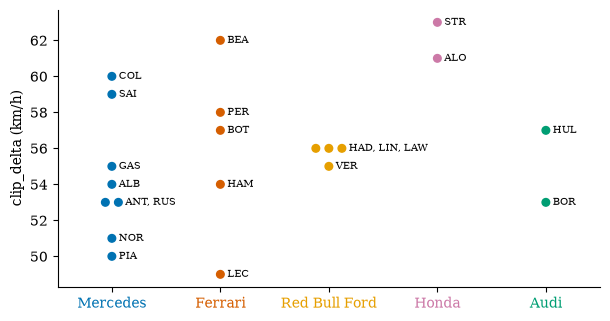

In [46]:
strip_plot(STRAIGHTS["T14→T16 via 130R"], "fig_t16_clip_delta_by_pu.pdf")

In [47]:
_d = STRAIGHTS["T14→T16 via 130R"]
caption("Figure", "strip16", f"clip_delta on the T14→T16 straight (through 130R) per driver, coloured by PU: {_d.clip_delta.min():.0f}–{_d.clip_delta.max():.0f} km/h "
        f"across {len(_d)} drivers. One or two cars per team and one lap each; no PU ranking is implied.")

*Figure 4. clip_delta on the T14→T16 straight (through 130R) per driver, coloured by PU: 49–63 km/h across 21 drivers. One or two cars per team and one lap each; no PU ranking is implied.*

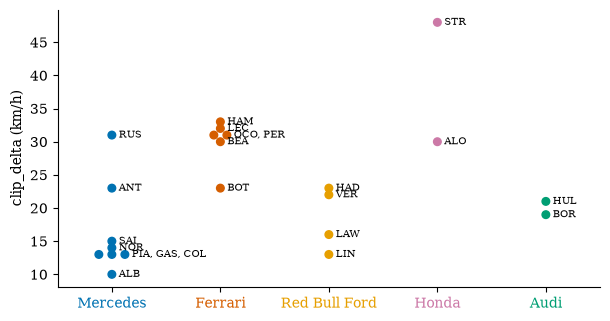

In [48]:
strip_plot(STRAIGHTS["T12→T13"], "fig_t13_clip_delta_by_pu.pdf")

In [49]:
_d = STRAIGHTS["T12→T13"]
caption("Figure", "strip13", f"clip_delta on the T12→T13 straight per driver, coloured by PU: {_d.clip_delta.min():.0f}–{_d.clip_delta.max():.0f} km/h "
        f"across {len(_d)} drivers; peaks {_d.peak_speed.min():.0f}–{_d.peak_speed.max():.0f} km/h, near the 290 km/h start of the C5.2.8 taper. "
        "One or two cars per team and one lap each; no PU ranking is implied.")

*Figure 5. clip_delta on the T12→T13 straight per driver, coloured by PU: 10–48 km/h across 22 drivers; peaks 281–301 km/h, near the 290 km/h start of the C5.2.8 taper. One or two cars per team and one lap each; no PU ranking is implied.*

## 9. Reference figures

**A. Circuit map** (after Bopaiah & Samuel, 2021, Fig. 4), drawn from one lap's position data, which freezes do not affect. Rotation and corner-label offsets follow the FastF1 example *Draw a track map with numbered corners* (`get_circuit_info().rotation`, corner `Angle`). Sectors from the lap's sector timestamps; measured straights from the median start/end positions of the selected segments. Panel B: every frozen car-data sample on every push lap, placed at the nearest position sample. **B. Taper**: the FIA power limits used for `taper_kw_at_peak`, with each selected segment's peak speed.

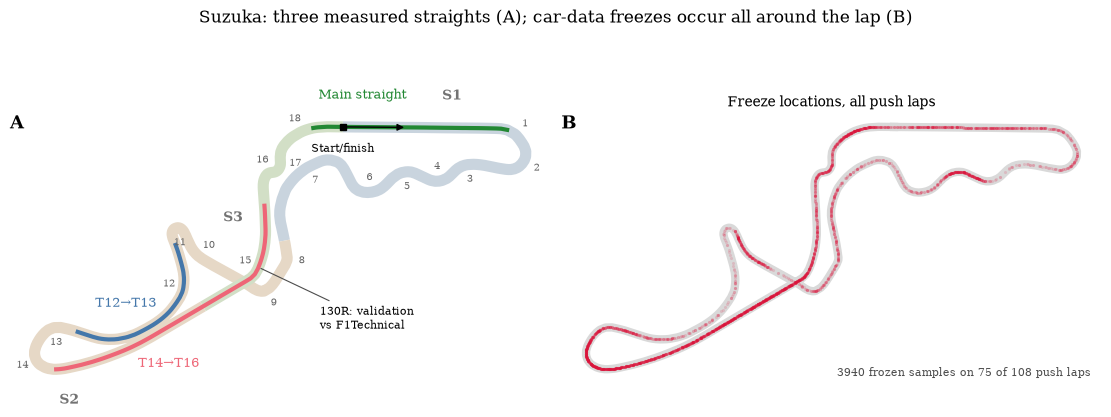

In [50]:
def rotate(xy, angle):
    """Rotate [n, 2] or [2] coordinates by `angle` radians (FastF1 track-map example)."""
    return np.matmul(xy, np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]]))


def place_label(ax, xy, idx, text, taken, dist=1300, **kw):
    """Write `text` beside the track near samples `idx`, at the candidate point (either side, `dist` units along the
    normal) furthest from the track and from points in `taken`; the chosen point is appended to `taken`."""
    best, best_gap = None, -1
    for i in idx:
        t = xy[min(i + 2, len(xy) - 1)] - xy[max(i - 2, 0)]
        nrm = np.array([-t[1], t[0]]) / np.hypot(*t)
        for sign in (1, -1):
            cand = xy[i] + sign * dist * nrm
            gap = np.hypot(*(np.vstack([xy, taken]) - cand).T).min()
            if gap > best_gap:
                best, best_gap = cand, gap
    taken.append(best)
    ax.text(*best, text, ha="center", va="center", **kw)


ci = s.get_circuit_info()
ang = ci.rotation / 180 * np.pi
ref = fastest["RUS"]
pos = lap_pos(ref)
xy, xyd = rotate(pos[["X", "Y"]].to_numpy(), ang), xy_cumdist(pos)
pt = pos["SessionTime"].dt.total_seconds().to_numpy()
i1, i2 = (int(np.abs(pt - ref[c].total_seconds()).argmin()) for c in ("Sector1SessionTime", "Sector2SessionTime"))

fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
taken = []
for n, c in corners.iterrows():
    off = rotate([600, 0], c.Angle / 180 * np.pi)
    pc = rotate([c.X + off[0], c.Y + off[1]], ang)
    axA.text(*pc, str(n), fontsize=7, color="0.4", ha="center", va="center")
    taken.append(pc)
p15 = rotate([corners.loc[15, "X"], corners.loc[15, "Y"]], ang)
note = p15 + np.array([2500, -2500])
axA.annotate("130R: validation\nvs F1Technical", xy=p15, xytext=note, fontsize=8, arrowprops=dict(arrowstyle="-", color="0.3", lw=0.8))
taken.append(note)
for (a, b), col, name in zip([(0, i1 + 1), (i1, i2 + 1), (i2, len(xy))], ["#c9d4de", "#e6d8c6", "#d2dfc6"], ["S1", "S2", "S3"]):
    axA.plot(*xy[a:b].T, color=col, lw=8, solid_capstyle="butt", zorder=1)
    place_label(axA, xy, np.linspace(a, b - 1, 7).astype(int)[1:-1], name, taken, fontsize=10, color="0.45", fontweight="bold")

ms = main_straight
spans = {"T13": [(straights.loc[straights.Label == "T13", "StartPos_m"].median(), straights.loc[straights.Label == "T13", "EndPos_m"].median())],
         "T16": [(straights.loc[straights.Label == "T16", "StartPos_m"].median(), straights.loc[straights.Label == "T16", "EndPos_m"].median())],
         "T1": [(xyd[-1] + ms.start_m.median(), xyd[-1]), (0, ms.end_m.median())]}
names = {"T13": "T12→T13", "T16": "T14→T16", "T1": "Main straight"}
for lab, parts in spans.items():
    for lo, hi in parts:
        m = (xyd >= lo) & (xyd <= hi)
        axA.plot(*xy[m].T, color=STRAIGHT_COLORS[lab], lw=3, zorder=2)
    lo, hi = parts[-1]
    i_mid = int(np.abs(xyd - (lo + hi) / 2).argmin())
    place_label(axA, xy, range(max(i_mid - 10, 0), min(i_mid + 11, len(xy)), 5), names[lab], taken, fontsize=9, color=STRAIGHT_COLORS[lab])

axA.plot(*xy[0], marker="s", color="black", ms=5, zorder=3)
axA.text(xy[0][0], xy[0][1] - 650, "Start/finish", fontsize=8, ha="center", va="top")
k = int(np.abs(xyd - 250).argmin())
axA.annotate("", xy=xy[k], xytext=xy[0], arrowprops=dict(arrowstyle="-|>", color="black", lw=1), zorder=4)

fx, fy, nlap = [], [], 0
for _, lap in push.iterlaps():
    car = lap.get_car_data()
    t_fz = car.loc[freeze_mask(car)[0], "SessionTime"].dt.total_seconds().to_numpy()
    if len(t_fz):
        nlap += 1
        p = lap.get_pos_data(pad=1, pad_side="both")
        j = np.abs(p["SessionTime"].dt.total_seconds().to_numpy()[:, None] - t_fz[None, :]).argmin(axis=0)
        r = rotate(p[["X", "Y"]].to_numpy()[j], ang)
        fx += list(r[:, 0]); fy += list(r[:, 1])
axB.plot(*xy.T, color="0.85", lw=6, zorder=1)
axB.scatter(fx, fy, s=5, color="crimson", alpha=0.15, lw=0, zorder=2)
axB.text(0.98, 0.02, f"{len(fx)} frozen samples on {nlap} of {len(push)} push laps", transform=axB.transAxes, fontsize=8, color="0.3", ha="right")

for ax, letter in [(axA, "A"), (axB, "B")]:
    ax.set_aspect("equal"); ax.axis("off")
    ax.text(0, 1, letter, transform=ax.transAxes, fontsize=13, fontweight="bold", va="top")
axB.set_title("Freeze locations, all push laps", fontsize=10)
fig.suptitle("Suzuka: three measured straights (A); car-data freezes occur all around the lap (B)", fontsize=12)
fig.savefig(FIG / "fig_suzuka_map.pdf")
plt.show()

In [51]:
caption("Figure", "map", f"Suzuka reference map. A: FIA sectors (muted), corner numbers, start/finish with direction of travel, the three measured straights, "
        f"and T15 (130R), used for Validation 2. B: {len(fx):,} flagged car-data samples (including 1-sample buffers) on {nlap} of {len(push)} push laps.")

*Figure 6. Suzuka reference map. A: FIA sectors (muted), corner numbers, start/finish with direction of travel, the three measured straights, and T15 (130R), used for Validation 2. B: 3,940 flagged car-data samples (including 1-sample buffers) on 75 of 108 push laps.*

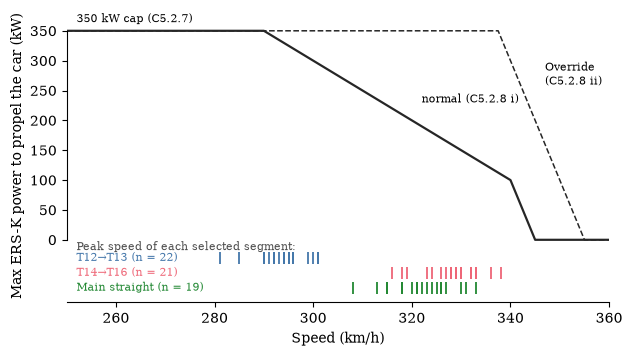

In [52]:
v = np.linspace(250, 360, 1101)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(v, taper_kw(v), color="0.15", lw=1.6)
ax.plot(v, np.minimum(np.where(v < 355, 7100 - 20 * v, 0), 350), color="0.15", lw=1.1, ls="--")  # C5.2.8 ii, C5.2.7 cap
ax.text(322, 230, "normal (C5.2.8 i)", fontsize=8)
ax.text(347, 260, "Override\n(C5.2.8 ii)", fontsize=8)
ax.text(252, 360, "350 kW cap (C5.2.7)", fontsize=8, va="bottom")
ax.text(252, -12, "Peak speed of each selected segment:", fontsize=8, va="center", color="0.3")

bands = {"T13": "T12→T13", "T16": "T14→T16", "T1": "Main straight"}
for i, (lab, name) in enumerate(bands.items()):
    pk = segments.loc[segments.Label == lab, "peak_speed"]
    y = -30 - 25 * i
    ax.plot(pk, np.full(len(pk), y), "|", ms=9, mew=1.3, color=STRAIGHT_COLORS[lab])
    ax.text(252, y, f"{name} (n = {len(pk)})", fontsize=8, va="center", color=STRAIGHT_COLORS[lab])
ax.set(xlim=(250, 360), ylim=(-105, 385), xlabel="Speed (km/h)", ylabel="Max ERS-K power to propel the car (kW)")
ax.set_yticks(range(0, 351, 50))
ax.spines["left"].set_bounds(0, 350)
fig.savefig(FIG / "fig_taper.pdf")
plt.show()

In [53]:
_pk = {k: segments.loc[segments.Label == k, "peak_speed"] for k in ["T13", "T16", "T1"]}
caption("Figure", "taper", "Maximum ERS-K power used to propel the car vs speed, FIA 2026 Technical Regulations Section C, Issue 12: C5.2.8 i (solid), "
        "Override C5.2.8 ii (dashed), both capped at 350 kW by C5.2.7. Ticks: peak speed of each selected segment; "
        + ", ".join(f"{n} {_pk[k].min():.0f}–{_pk[k].max():.0f} km/h" for k, n in [("T13", "T12→T13"), ("T16", "T14→T16"), ("T1", "main straight")]) + ".")

*Figure 7. Maximum ERS-K power used to propel the car vs speed, FIA 2026 Technical Regulations Section C, Issue 12: C5.2.8 i (solid), Override C5.2.8 ii (dashed), both capped at 350 kW by C5.2.7. Ticks: peak speed of each selected segment; T12→T13 281–301 km/h, T14→T16 316–338 km/h, main straight 308–333 km/h.*

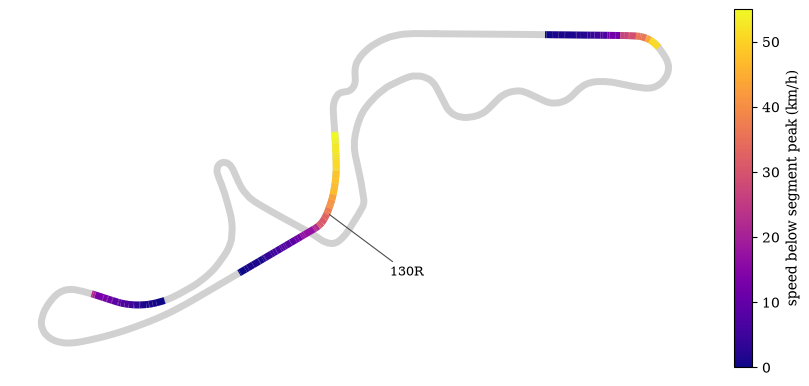

In [54]:
from matplotlib.collections import LineCollection

map_lap = push[(push.Driver == drv) & (push.LapNumber == lapno)].iloc[0]  # the freeze-free full lap of Section 6.3
map_car = map_lap.get_car_data().add_distance()
assert not freeze_mask(map_car)[0].any()
map_loss = pd.Series(np.nan, index=map_car.index)  # speed below the segment's peak, from the peak to the segment end
for a, b in full_throttle_segments(map_car, map_lap["Time"]):
    sp = map_car["Speed"].to_numpy()[a:b]
    k = a + len(sp) - 1 - int(np.argmax(sp[::-1]))  # peak = last sample at maximum speed, as in segment_metrics
    map_loss.iloc[k:b] = sp.max() - map_car["Speed"].to_numpy()[k:b]

# merged telemetry is used for drawing only (HAC); loss values come from the raw car data, nearest sample in time
tel = map_lap.telemetry[["SessionTime", "X", "Y"]].sort_values("SessionTime")
tel = pd.merge_asof(tel, pd.DataFrame({"SessionTime": map_car["SessionTime"], "Loss": map_loss.to_numpy()}),
                    on="SessionTime", direction="nearest")
pts = rotate(tel[["X", "Y"]].to_numpy(), ang).reshape(-1, 1, 2)
segs = np.concatenate([pts[:-1], pts[1:]], axis=1)  # FastF1 example "Speed visualization on track map"
on = tel["Loss"].notna().to_numpy()
keep = on[:-1] & on[1:]

fig, ax = plt.subplots(figsize=(8, 5.2), layout="constrained")
ax.plot(pts[:, 0, 0], pts[:, 0, 1], color="0.82", lw=5, zorder=1, solid_capstyle="round")
lc = LineCollection(segs[keep], cmap="plasma", norm=plt.Normalize(0, np.nanmax(map_loss)), lw=5, zorder=2)
lc.set_array(tel["Loss"].to_numpy()[:-1][keep])
ax.add_collection(lc)
fig.colorbar(lc, ax=ax, shrink=0.7, label="speed below segment peak (km/h)")
p15 = rotate([corners.loc[15, "X"], corners.loc[15, "Y"]], ang)
ax.annotate("130R", xy=p15, xytext=p15 + np.array([2000, -2000]), fontsize=9, arrowprops=dict(arrowstyle="-", color="0.3", lw=0.8))
ax.set_aspect("equal")
ax.axis("off")
fig.savefig(FIG / "fig_suzuka_clipping_map.pdf")
plt.show()

In [55]:
_seg = straights[(straights.Driver == drv) & (straights.LapNumber == lapno)]
caption("Figure", "clipmap", f"Suzuka clipping map, {drv} lap {lapno} ({map_lap['QualiPart']}, freeze-free): colour = speed below the segment's peak, "
        f"from the peak to the segment end (where clip_delta is measured); grey = outside full-throttle segments or before the peak. Largest loss "
        f"{np.nanmax(map_loss):.0f} km/h" + (f"; clip_delta on this lap: " + ", ".join(f"ending {r.Label} {r.clip_delta:.0f} km/h" for r in _seg.itertuples())
                                             if len(_seg) else "") + ". 130R = T15.")

*Figure 8. Suzuka clipping map, RUS lap 14 (Q2, freeze-free): colour = speed below the segment's peak, from the peak to the segment end (where clip_delta is measured); grey = outside full-throttle segments or before the peak. Largest loss 55 km/h. 130R = T15.*

## 10. Pipeline function

`run_session(year, event)` runs the whole chain above for one qualifying session (load, Validation 1, freeze flags, push-lap selection, sectors and PKE, segments and metrics, coverage, exclusion log) and returns the tables plus a QC summary. Event-specific checks (Validation 2 at 130R) stay outside. Japan is rerun through it and checked against the notebook.

In [56]:
tables_jp, qc_jp = run_session(2026, "Japan", OFFICIAL_LENGTH_M, OPENF1_SESSION)
notebook = {"drivers": len(fastest), "timed_laps": len(timed), "push_laps": len(push), "lap_exclusions": len(lap_log),
            "v1_car_mean_abs_err_pct": v1["CarData_err%"].abs().mean(), "v1_car_max_abs_err_pct": v1["CarData_err%"].abs().max(),
            "v1_xy_mean_abs_err_pct": v1["XY_err%"].abs().mean(), "v1_xy_max_abs_err_pct": v1["XY_err%"].abs().max(),
            "push_lap_frozen_pct_mean": qc.loc[qc.Push, "FrozenPct"].mean(),
            "sectors_computed": len(sec_all), "sectors_dropped": int(sec_all.Frozen.sum()), "sectors_selected": len(sectors),
            "segments_detected": len(seg_all), "segments_dropped": len(seg_log), "straights_selected": len(straights),
            "main_straight_ok": int((ms_all.Status == "ok").sum()), "main_straight_drivers": len(main_straight),
            "segment_rows": len(segments), "selected_segments_jump_flagged": int(segments.JumpFlag.sum())}
check = pd.DataFrame({"notebook": notebook, "run_session": {k: qc_jp[k] for k in notebook}})
check["match"] = [np.isclose(a, b) for a, b in zip(check.notebook, check.run_session)]
print(f"Brake source: {qc_jp['brake_source']}")
print(check.round(3).to_string())
assert check["match"].all()
pd.testing.assert_frame_equal(tables_jp["sectors"].reset_index(drop=True), sectors.reset_index(drop=True))
pd.testing.assert_frame_equal(tables_jp["segments"].reset_index(drop=True), segments.reset_index(drop=True))
print("\nAll headline numbers and the sectors/segments tables match.\n")
print(tables_jp["exclusions"].groupby(["Scope", "Reason"]).size().rename("rows").to_string())

Brake source: OpenF1
                                notebook  run_session  match
drivers                           22.000       22.000   True
timed_laps                       227.000      227.000   True
push_laps                        108.000      108.000   True
lap_exclusions                   119.000      119.000   True
v1_car_mean_abs_err_pct            1.483        1.483   True
v1_car_max_abs_err_pct             7.366        7.366   True
v1_xy_mean_abs_err_pct             0.584        0.584   True
v1_xy_max_abs_err_pct              0.827        0.827   True
push_lap_frozen_pct_mean          10.602       10.602   True
sectors_computed                 432.000      432.000   True
sectors_dropped                  241.000      241.000   True
sectors_selected                  75.000       75.000   True
segments_detected                313.000      313.000   True
segments_dropped                 165.000      165.000   True
straights_selected                43.000       43.000   True
mai

In [57]:
caption("Table", "pipeline", f'run_session(2026, "Japan") vs the notebook: {int(check["match"].sum())} of {len(check)} headline numbers match, and the '
        f"sectors and segments tables are identical; brake source: {qc_jp['brake_source']}.")

*Table 18. run_session(2026, "Japan") vs the notebook: 19 of 19 headline numbers match, and the sectors and segments tables are identical; brake source: OpenF1.*

## 11. Robustness: implausible-jump flag

Results are reported under two justifiable processing choices, following the multiverse approach of Steegen et al. (2016, *Perspectives on Psychological Science* 11, 702–712): **primary** (documented sentinels only) and **excluding JumpFlag segments**, where a segment with an implausible Speed jump between the sample before its first peak-speed sample and its end counts as unusable and each driver's next-best clean lap is used instead.

**Limitation.** Implausible jumps before the peak do not affect clip_delta or decel_rate, which run from the peak to the segment end, but they do affect segment and sector PKE (a secondary metric).

In [58]:
_, straights_alt, main_alt, segments_alt = select_clean(sec_all, seg_all, ms_all, exclude_jumps=True)
print(f"Selected segments with JumpFlag (primary): {int(segments.JumpFlag.sum())} of {len(segments)}; "
      f"rows after excluding flagged segments: {len(segments_alt)}\n")

M10 = ["peak_speed", "end_speed", "clip_delta", "clip_distance", "decel_rate", "vmax_position"]
VERSIONS = [("primary", segments), ("excl. flagged", segments_alt)]


def by_straight(d):
    return d.assign(Straight=np.where(d.CrossesTimingLine, "Main (T1)", d.Label)).groupby("Straight")


print("Drivers per straight:")
print(pd.DataFrame({k: by_straight(d).Driver.nunique() for k, d in VERSIONS}).to_string(), "\n")
t10 = pd.concat({k: by_straight(d)[M10].mean().stack() for k, d in VERSIONS}, axis=1)
t10["difference"] = t10["excl. flagged"] - t10["primary"]
print("Table 10, both ways:")
print(t10.round(2).to_string(), "\n")

cmp_alt, mad_alt = validation2(segments_alt)
t13 = pd.DataFrame({"primary": cmp.Clean_Drop_Min100, "excl. flagged": cmp_alt.Clean_Drop_Min100,
                    "primary (seg. end)": cmp.Clean_Drop_MinEnd, "excl. flagged (seg. end)": cmp_alt.Clean_Drop_MinEnd,
                    "F1T": cmp.F1T_Drop})
print("Table 13, cleaned drops at 130R (km/h):")
print(t13.round(1).to_string())
m = pd.DataFrame({"primary": mad.loc["Clean", "Drop"], "excl. flagged": mad_alt.loc["Clean", "Drop"]})
m["difference"] = m["excl. flagged"] - m["primary"]
print("Mean absolute drop difference vs F1Technical, by window:")
print(m.round(1).to_string(), "\n")

cs = pd.concat({k: comparison_summary(straight_tables(d)) for k, d in VERSIONS})
print("STDD / SPDT summary (clip_delta, km/h):")
print(cs.round(1).to_string())

Selected segments with JumpFlag (primary): 1 of 62; rows after excluding flagged segments: 61

Drivers per straight:
           primary  excl. flagged
Straight                         
Main (T1)       19             19
T13             22             22
T16             21             20 

Table 10, both ways:
                         primary  excl. flagged  difference
Straight                                                   
Main (T1) peak_speed      321.89         321.89        0.00
          end_speed       284.47         284.47        0.00
          clip_delta       37.42          37.42        0.00
          clip_distance   295.93         295.93        0.00
          decel_rate       12.57          12.57        0.00
          vmax_position     0.63           0.63        0.00
T13       peak_speed      293.41         293.41        0.00
          end_speed       270.50         270.50        0.00
          clip_delta       22.91          22.91        0.00
          clip_distance   248.

Table 13, cleaned drops at 130R (km/h):
                primary excl. flagged primary (seg. end) excl. flagged (seg. end)  F1T
Audi               45.0          45.0               55.0                     55.0   51
Aston Martin       44.5          47.0               62.0                     61.0   60
Red Bull Racing    41.5          41.5               55.5                     55.5   56
Racing Bulls       44.0          44.0               56.0                     56.0   57
Alpine             47.0          47.0               57.5                     57.5   55
Mercedes           45.5          45.5               53.0                     53.0   58
Mean absolute drop difference vs F1Technical, by window:
        primary  excl. flagged  difference
Window                                    
Min100     11.6           11.2        -0.4
MinEnd      2.5            2.3        -0.2 

STDD / SPDT summary (clip_delta, km/h):
                                                   drivers  STDD pairs  STDD mea

In [59]:
_flag = segments[segments.JumpFlag]
_dc = t10.xs("clip_delta", level=1)["difference"].abs().max()
_dd = (t13.drop(columns="F1T").diff(axis=1).iloc[:, [1, 3]]).abs().max().max()
caption("Table", "robust", f"Robustness to the implausible-jump flag: {len(_flag)} of {len(segments)} selected segments flagged "
        f"({', '.join(f'{r.Driver} {r.Label} lap {r.LapNumber}' for r in _flag.itertuples()) or 'none'}). Excluding them changes mean clip_delta per "
        f"straight by up to {_dc:.1f} km/h, team drops at 130R by up to {_dd:.1f} km/h and the mean absolute difference from F1Technical by up to "
        f"{m['difference'].abs().max():.1f} km/h.")

*Table 19. Robustness to the implausible-jump flag: 1 of 62 selected segments flagged (STR T16 lap 8). Excluding them changes mean clip_delta per straight by up to 0.4 km/h, team drops at 130R by up to 2.5 km/h and the mean absolute difference from F1Technical by up to 0.4 km/h.*

## Appendix A: OpenF1 comparison

FastF1 car data compared sample by sample with OpenF1 `car_data` for the same UTC window (matched within 20 ms). A1: ANT's longest freeze. A2: the window before STR's lap-8 T14→T16 segment, where FastF1 shows Brake = True at Throttle = 100. A3: the raw OpenF1 brake value of every FastF1 Brake = True sample at full throttle outside 104 freezes. Not part of the pipeline.

In [60]:
def openf1_window(lap, car):
    """OpenF1 car_data for the UTC span of `car`, matched to its samples within 20 ms."""
    url = (f"https://api.openf1.org/v1/car_data?session_key={OPENF1_SESSION}&driver_number={lap['DriverNumber']}"
           f"&date>={car['Date'].iloc[0]:%Y-%m-%dT%H:%M:%S.%f}&date<={car['Date'].iloc[-1]:%Y-%m-%dT%H:%M:%S.%f}")
    of = pd.DataFrame(json.load(urllib.request.urlopen(url)))
    of["Date"] = pd.to_datetime(of["date"], format="ISO8601").dt.tz_localize(None).astype(car["Date"].dtype)
    m = pd.merge_asof(car, of.assign(OpenF1Date=of["Date"]).sort_values("Date"), on="Date", direction="nearest")
    return of, m[(m["Date"] - m["OpenF1Date"]).abs() <= pd.Timedelta(milliseconds=20)]


lap = fastest["ANT"]
car = lap.get_car_data()
_, core, run_id = freeze_mask(car)
ff = car.loc[run_id == run_id[(car["Throttle"] == SENTINEL)].value_counts().idxmax(), ["Date", "Speed", "RPM", "nGear", "Throttle"]]
of, m = openf1_window(lap, ff)
same = all((m[a] == m[b]).all() for a, b in [("Speed", "speed"), ("RPM", "rpm"), ("nGear", "n_gear"), ("Throttle", "throttle")])
print(f"A1 ANT: FastF1 samples: {len(ff)}, OpenF1 samples: {len(of)}, matched: {len(m)}, all channels identical: {same}")
print("OpenF1 values:", {c: sorted(of[c].unique().tolist()) for c in ["speed", "rpm", "n_gear", "throttle", "brake"]})

A1 ANT: FastF1 samples: 96, OpenF1 samples: 96, matched: 96, all channels identical: True
OpenF1 values: {'speed': [189], 'rpm': [11535], 'n_gear': [4], 'throttle': [80, 104], 'brake': [0, 104]}


In [61]:
caption("Table A", "a1", f"ANT's longest freeze: {len(m)} of {len(ff)} FastF1 samples matched in OpenF1, all channels identical: {same}; "
        f"OpenF1 brake values in the window: {sorted(of['brake'].unique().tolist())}.")

*Table A1. ANT's longest freeze: 96 of 96 FastF1 samples matched in OpenF1, all channels identical: True; OpenF1 brake values in the window: [0, 104].*

In [62]:
lap = push[(push.Driver == "STR") & (push.LapNumber == 8)].iloc[0]
car = lap.get_car_data().add_distance()
w = car[car["Distance"].between(4380, 4640)][["Date", "Distance", "Speed", "RPM", "nGear", "Throttle", "Brake"]]
of, m = openf1_window(lap, w)
print(f"A2 STR lap 8: FastF1 samples: {len(w)}, OpenF1 samples: {len(of)}, matched: {len(m)}")
print(m[["Distance", "Speed", "RPM", "nGear", "Throttle", "Brake", "speed", "rpm", "n_gear", "throttle", "brake"]].round(1).to_string(index=False))

A2 STR lap 8: FastF1 samples: 14, OpenF1 samples: 14, matched: 14
 Distance  Speed     RPM  nGear  Throttle  Brake  speed   rpm  n_gear  throttle  brake
   4386.6  302.0 10462.0      8     100.0  False    302 10462       8       100      0
   4410.1  302.0 10443.0      8     100.0  False    302 10443       8       100      0
   4440.3  302.0 10673.0      8     100.0  False    302 10673       8       100      0
   4453.8  305.0 10673.0      8     100.0  False    305 10673       8       100      0
   4487.7  305.0 10673.0      8     100.0   True    305 10673       8       100    104
   4504.7  305.0 10673.0      8     100.0   True    305 10673       8       100    104
   4521.6  305.0 10657.0      8     100.0   True    305 10657       8       100    104
   4541.9  305.0 10657.0      8     100.0   True    305 10657       8       100    104
   4558.9  305.0 10657.0      8     100.0   True    305 10657       8       100    104
   4579.2  305.0 10657.0      8     100.0   True    305 10657   

In [63]:
caption("Table A", "a2", f"STR lap 8 before the T14→T16 straight: OpenF1 reports brake == {SENTINEL} on {(m['brake'] == SENTINEL).sum()} samples "
        f"where FastF1 shows Brake = True at Throttle = {m.loc[m['brake'] == SENTINEL, 'Throttle'].max():.0f}; FastF1 Speed holds "
        f"{m.loc[m['brake'] == SENTINEL, 'Speed'].min():.0f} km/h, then reaches {m['Speed'].max():.0f} km/h.")

*Table A2. STR lap 8 before the T14→T16 straight: OpenF1 reports brake == 104 on 7 samples where FastF1 shows Brake = True at Throttle = 100; FastF1 Speed holds 305 km/h, then reaches 316 km/h.*

In [64]:
cal = []
for _, lap in push.iterlaps():
    car = lap.get_car_data()
    hit = car["Brake"] & car["Throttle"].between(FULL_THROTTLE, 100) & ~freeze_mask(car)[0]
    speed_run = car["Speed"].ne(car["Speed"].shift()).cumsum()
    cal.append(pd.DataFrame({"OpenF1_brake": openf1_brake(car)[hit],
                             "InUnchangedSpeedRun": speed_run.map(speed_run.value_counts())[hit] >= 2}))
cal = pd.concat(cal)
print(f"A3: FastF1 Brake = True at Throttle 98-100 outside 104 freezes, push laps: {len(cal)} samples; "
      f"matched in OpenF1: {cal.OpenF1_brake.notna().sum()}")
print(pd.crosstab(cal.InUnchangedSpeedRun, cal.OpenF1_brake, margins=True).to_string())

A3: FastF1 Brake = True at Throttle 98-100 outside 104 freezes, push laps: 167 samples; matched in OpenF1: 167
OpenF1_brake         100  104  All
InUnchangedSpeedRun               
False                 70   10   80
True                  22   65   87
All                   92   75  167


In [65]:
_ct = pd.crosstab(cal.InUnchangedSpeedRun, cal.OpenF1_brake)
caption("Table A", "a3", f"{len(cal)} FastF1 Brake = True samples at full throttle outside 104 freezes: OpenF1 brake 100 (genuine) {_ct[100].sum()}, "
        f"{SENTINEL} (sentinel) {_ct[SENTINEL].sum()}. A FastF1-only substitute (inside an unchanged-Speed run) would catch {_ct.loc[True, SENTINEL]} of "
        f"{_ct[SENTINEL].sum()} sentinel samples with {_ct.loc[True, 100]} false positives; it is not used.")

*Table A3. 167 FastF1 Brake = True samples at full throttle outside 104 freezes: OpenF1 brake 100 (genuine) 92, 104 (sentinel) 75. A FastF1-only substitute (inside an unchanged-Speed run) would catch 65 of 75 sentinel samples with 22 false positives; it is not used.*

## Appendix B: diagnostics

Evidence behind the decisions above, kept for reproducibility.

**B1. Distance-error causes on fastest laps.** `add_distance` integrates `Speed / 3.6 · dt` with `dt[0] = Time[0]` (core.py), so gaps are counted at the post-gap speed, the lap start is covered and the stretch from the last sample to the lap end is not. With `pad=1`, `Time` stays relative to lap start, so the pad sample has negative `Time` and is not double-counted.

In [66]:
def unchanged_runs(car, cols, end):
    """Runs of consecutive samples with all `cols` unchanged: i0, i1, samples, duration (s)."""
    new = car[cols].ne(car[cols].shift()).any(axis=1).to_numpy()
    t = np.append(car["SessionTime"].dt.total_seconds().to_numpy(), end.total_seconds())
    i0 = np.flatnonzero(new)
    i1 = np.append(i0[1:], len(car))
    return pd.DataFrame(dict(i0=i0, i1=i1, n=i1 - i0, Duration_s=t[i1] - t[i0]))


diag = []
for d, lap in fastest.items():
    raw = lap.get_car_data().add_distance()
    pad = lap.get_car_data(pad=1, pad_side="both").add_distance()
    sl = pad.slice_by_lap(lap, interpolate_edges=True)
    t = raw["SessionTime"].dt.total_seconds()
    tail = lap["Time"].total_seconds() - t.iloc[-1]
    flag, core, run_id = freeze_mask(raw)
    starts_full = run_id.map(raw.groupby(run_id)["Throttle"].first()).between(98, 100)
    diag.append(dict(Driver=d, Head_s=t.iloc[0] - lap["LapStartTime"].total_seconds(), Tail_s=tail,
                     Gaps_over_0p5s=int((t.diff() > 0.5).sum()), MaxGap_s=t.diff().max(),
                     LongestSpeedRun=unchanged_runs(raw, ["Speed"], lap["Time"]).n.max(),
                     PadTime0_s=pad["Time"].iloc[0].total_seconds(),
                     PadMinusRaw_m=sl["Distance"].iloc[-1] - sl["Distance"].iloc[0] - raw["Distance"].iloc[-1],
                     TailExpected_m=raw["Speed"].iloc[-1] / 3.6 * tail,
                     Frozen_n=int(flag.sum()), FrozenFromFullThrottle_n=int((core & starts_full).sum())))
b1 = pd.DataFrame(diag).set_index("Driver")
print(b1.round(2).to_string())

        Head_s  Tail_s  Gaps_over_0p5s  MaxGap_s  LongestSpeedRun  PadTime0_s  PadMinusRaw_m  TailExpected_m  Frozen_n  FrozenFromFullThrottle_n
Driver                                                                                                                                          
ANT       0.01    0.05               6      1.08               96       -0.15           2.63            2.63       109                        10
RUS       0.16    0.16               5      1.08               14       -0.08          11.62           11.45        16                        14
PIA       0.09    0.00               2      1.08                4       -0.07           0.18            0.15         0                         0
LEC       0.02    0.01               5      1.08               14       -0.14           0.44            0.45        16                        14
NOR       0.13    0.08               3      1.08                6       -0.07           6.11            6.05         0            

In [67]:
caption("Table B", "b1", f"Distance-error causes on fastest laps: first/last samples within {max(b1.Head_s.max(), b1.Tail_s.max()):.2f} s of the lap "
        f"boundaries; padded − unpadded equals the uncovered tail within {(b1.PadMinusRaw_m - b1.TailExpected_m).abs().max():.1f} m; most frozen samples: "
        + ", ".join(f"{d} {n}" for d, n in b1.Frozen_n.nlargest(3).items()) + ".")

*Table B1. Distance-error causes on fastest laps: first/last samples within 0.41 s of the lap boundaries; padded − unpadded equals the uncovered tail within 0.4 m; most frozen samples: COL 137, OCO 129, HUL 126.*

**B2. Why the freeze is seeded on 104 rather than on all channels being unchanged.** Throttle and Brake switch to 104 inside a freeze, so requiring all five channels to be unchanged splits one freeze into several runs.

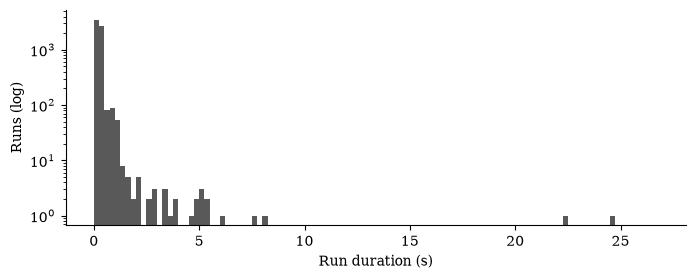

Longest Speed-only run outside ANT/BOR: ALB, 36 samples, 9.1 s at 308 km/h; distinct values: {'Speed': 1, 'RPM': 1, 'nGear': 1, 'Throttle': 2, 'Brake': 2}


In [68]:
CH = ["Speed", "RPM", "nGear", "Throttle", "Brake"]
r5 = pd.concat([unchanged_runs(lap.get_car_data(), CH, lap["Time"]).assign(Driver=d) for d, lap in fastest.items()])
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(r5["Duration_s"], bins=np.arange(0, 27, 0.25), log=True, color="0.35")
ax.set(xlabel="Run duration (s)", ylabel="Runs (log)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

rs = pd.concat([unchanged_runs(lap.get_car_data(), ["Speed"], lap["Time"]).assign(Driver=d)
                for d, lap in fastest.items() if d not in ("ANT", "BOR")]).sort_values("n").iloc[-1]
seg = fastest[rs.Driver].get_car_data().iloc[int(rs.i0):int(rs.i1)]
print(f"Longest Speed-only run outside ANT/BOR: {rs.Driver}, {int(rs.n)} samples, {rs.Duration_s:.1f} s at {seg.Speed.iloc[0]:.0f} km/h; "
      f"distinct values: {seg[CH].nunique().to_dict()}")

In [69]:
caption("Figure B", "fb1", f"Durations of runs with all five channels unchanged (fastest laps): {(r5.Duration_s < 1).mean():.0%} last < 1 s; longest "
        f"{', '.join(f'{x:.1f}' for x in r5.Duration_s.nlargest(3))} s. {rs.Driver}'s {rs.Duration_s:.1f} s Speed-only run is split because Throttle "
        "and Brake change inside it, so the freeze is seeded on 104 instead.")

*Figure B1. Durations of runs with all five channels unchanged (fastest laps): 99% last < 1 s; longest 24.6, 22.5, 8.2 s. ALB's 9.1 s Speed-only run is split because Throttle and Brake change inside it, so the freeze is seeded on 104 instead.*

**B3. Where the two longest freezes sit on the lap.** Lap position from X/Y path length; corners placed by nearest X/Y point on the same lap.

In [70]:
b3 = []
for d in ["ANT", "BOR"]:
    lap = fastest[d]
    car = lap.get_car_data().add_distance()
    pos = lap_pos(lap)
    xyd, pt = xy_cumdist(pos), pos["SessionTime"].dt.total_seconds().to_numpy()
    i0, i1, t0, t1 = max(blocks(car, freeze_mask(car)[1], lap["Time"]), key=lambda b: b[1] - b[0])
    tc = car["SessionTime"].dt.total_seconds()
    d0, d1 = (xyd[np.abs(pt - x).argmin()] for x in (tc.iloc[i0 - 1], t1))
    car_m = car["Distance"].iloc[i1 - 1] - car["Distance"].iloc[i0 - 1] + car["Speed"].iloc[i1 - 1] / 3.6 * (t1 - tc.iloc[i1 - 1])
    inside = [f"T{n}" for n, c in corners.iterrows() if d0 <= xyd[np.hypot(pos.X - c.X, pos.Y - c.Y).argmin()] <= d1]
    b3.append(dict(Driver=d, frozen_s=t1 - t0, corners=inside, car_m=car_m, xy_m=d1 - d0))
    print(f"{d}: {t1 - t0:.1f} s frozen, lap position {d0:.0f}-{d1:.0f} m (X/Y), corners {', '.join(inside)}; "
          f"distance over window: car data {car_m:.0f} m vs X/Y {d1 - d0:.0f} m")

ANT: 25.8 s frozen, lap position 3979-5769 m (X/Y), corners T15, T16, T17, T18; distance over window: car data 1380 m vs X/Y 1789 m
BOR: 24.0 s frozen, lap position 3273-5087 m (X/Y), corners T13, T14, T15; distance over window: car data 1898 m vs X/Y 1814 m


In [71]:
caption("Table B", "b3", "The two longest freezes on fastest laps: " + "; ".join(
    f"{r['Driver']} {r['frozen_s']:.1f} s over {', '.join(r['corners'])} (car data {r['car_m'] - r['xy_m']:+.0f} m vs X/Y)" for r in b3) + ".")

*Table B2. The two longest freezes on fastest laps: ANT 25.8 s over T15, T16, T17, T18 (car data -409 m vs X/Y); BOR 24.0 s over T13, T14, T15 (car data +84 m vs X/Y).*

**B4. Frozen share of every timed lap** (driver × lap number; `*` = push lap).

In [72]:
v = qc.assign(v=qc.FrozenPct.round().astype(int).astype(str) + np.where(qc.Push, "*", ""))
print(v.pivot(index="Driver", columns="LapNumber", values="v").reindex(list(fastest)).fillna(".").to_string())

LapNumber   2   3   4    5   6    7    8   9    10   11   12   13   14  15  16   17 18   19   20  21
Driver                                                                                              
ANT         0*   4   .   5*   9    .  24*  17    .  33*   66    .  32*  10   .    .  .    .    .   .
RUS         0*   2   .  23*  20    .   1*   3    .  11*    7    2   0*   4   .   5*  0    .  15*  14
PIA         2*   0  2*    2   .  14*    4   .   0*    3    .  19*   16   .  0*    2  .  13*   10   .
LEC        21*  11   0   0*   3    .   5*   0    .   5*    0    .   0*   0   .   0*  .    .    .   .
NOR         0*   2  0*    5   .  26*    8   .   0*    3    .  12*   13   .  0*    3  .   1*    2   .
HAM         2*   2   3   2*   4    .   0*   2    .   0*    2   0*    2   .  0*    0  .   0*    0   .
GAS         2*   4   .  10*  11    .  13*  13    .  23*   23    .   8*  10   .  10*  4    .    .   .
HAD         1*   4   .  15*  10    .   0*   0    .   7*    5    .   4*   3   .    2  .    .

In [73]:
_pq = qc[qc.Push].groupby("Driver")["FrozenPct"]
caption("Table B", "b4", f"Frozen share of every timed lap (* = push lap): it varies from lap to lap; {((_pq.min() == 0) & (_pq.max() > 0)).sum()} of "
        f"{_pq.ngroups} drivers have both a freeze-free and a frozen push lap.")

*Table B3. Frozen share of every timed lap (* = push lap): it varies from lap to lap; 16 of 22 drivers have both a freeze-free and a frozen push lap.*

**B5. Stale runs without the sentinel.** A run of unchanged Speed + RPM + nGear lasting >= 1.5 s that contains no `Throttle == 104` is not flagged by the freeze definition. Checked on STR's two selected straights, then on every selected segment.

STR T13 (lap 5, Q1, flagged frozen: False): segment 2946-3701 m, peak 285 km/h at vmax_position 0.59, clip_delta 48, PKE 6.39
  no stale run >= 1.5 s
STR T16 (lap 8, Q1, flagged frozen: False): segment 4022-5241 m, peak 316 km/h at vmax_position 0.51, clip_delta 63, PKE 4.22
  no stale run >= 1.5 s


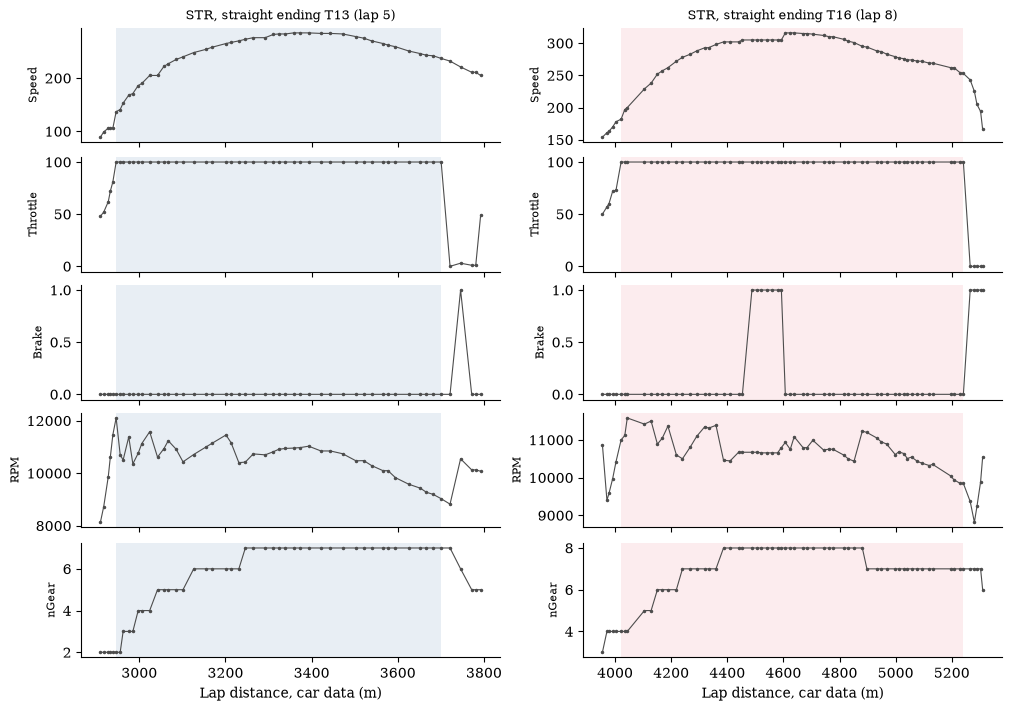

In [74]:
def segment_car(row):
    """Car data, end time and sample range [i0, i1) of one selected segment."""
    lap = push[(push.Driver == row.Driver) & (push.LapNumber == row.LapNumber)].iloc[0]
    main = getattr(row, "CrossesTimingLine", False)
    car = line_window(s, lap)[0] if main else lap.get_car_data().add_distance()
    end = car["SessionTime"].iloc[-1] if main else lap["Time"]
    i = np.flatnonzero((car["Distance"] >= row.start_m) & (car["Distance"] <= row.end_m))
    return car, end, i[0], i[-1] + 1


def stale_runs(car, end, i0, i1, min_s=1.5):
    """Unchanged Speed+RPM+nGear runs lasting >= min_s that overlap samples [i0, i1), and whether each contains 104."""
    r = unchanged_runs(car, ["Speed", "RPM", "nGear"], end)
    r = r[(r.Duration_s >= min_s) & (r.i0 < i1) & (r.i1 > i0)].copy()
    r["Has104"] = [bool((car["Throttle"].iloc[a:b] == SENTINEL).any()) for a, b in zip(r.i0, r.i1)]
    r["Speed"], r["Gear"], r["Dist_m"] = car["Speed"].iloc[r.i0].values, car["nGear"].iloc[r.i0].values, car["Distance"].iloc[r.i0].values
    return r


str_rows = seg_all[(seg_all.Driver == "STR") & (((seg_all.Label == "T13") & (seg_all.LapNumber == 5)) |
                                                  ((seg_all.Label == "T16") & (seg_all.LapNumber == 8)))]  # laps under review
fig, axes = plt.subplots(5, len(str_rows), figsize=(10, 7), sharex="col", layout="constrained", squeeze=False)
for col, row in enumerate(str_rows.itertuples()):
    car, end, i0, i1 = segment_car(row)
    seg = car.iloc[max(i0 - 5, 0):i1 + 5]
    r = stale_runs(car, end, i0, i1)
    print(f"STR {row.Label} (lap {row.LapNumber}, {row.QualiPart}, flagged frozen: {row.Frozen}): segment {row.start_m:.0f}-{row.end_m:.0f} m, "
          f"peak {row.peak_speed:.0f} km/h at vmax_position {row.vmax_position:.2f}, clip_delta {row.clip_delta:.0f}, PKE {row.pke:.2f}")
    print(r[["n", "Duration_s", "Speed", "Gear", "Dist_m", "Has104"]].round(2).to_string(index=False) if len(r) else "  no stale run >= 1.5 s")
    for ax, ch in zip(axes[:, col], ["Speed", "Throttle", "Brake", "RPM", "nGear"]):
        ax.plot(seg["Distance"], seg[ch].astype(float), ".-", ms=3, lw=0.8, color="0.3")
        ax.axvspan(row.start_m, row.end_m, color=STRAIGHT_COLORS[row.Label], alpha=0.12, lw=0)
        for a, b in zip(r.i0, r.i1):
            ax.axvspan(car["Distance"].iloc[a], car["Distance"].iloc[min(b, len(car) - 1)], color="orange", alpha=0.35, lw=0)
        ax.set_ylabel(ch, fontsize=8)
    axes[0, col].set_title(f"STR, straight ending {row.Label} (lap {row.LapNumber})", fontsize=9)
    axes[-1, col].set_xlabel("Lap distance, car data (m)")
plt.show()

In [75]:
caption("Figure B", "fb2", "STR's two reviewed straights (shaded: segment; orange: stale run >= 1.5 s): " + "; ".join(
    f"{r.Label} lap {r.LapNumber}: {r.start_m:.0f}–{r.end_m:.0f} m, peak {r.peak_speed:.0f} km/h, clip_delta {r.clip_delta:.0f}, frozen {r.Frozen}, JumpFlag {r.JumpFlag}"
    for r in str_rows.itertuples()) + ". OpenF1 shows the brake sentinel before the lap-8 peak (Appendix A).")

*Figure B2. STR's two reviewed straights (shaded: segment; orange: stale run >= 1.5 s): T13 lap 5: 2946–3701 m, peak 285 km/h, clip_delta 48, frozen False, JumpFlag False; T16 lap 8: 4022–5241 m, peak 316 km/h, clip_delta 63, frozen False, JumpFlag True. OpenF1 shows the brake sentinel before the lap-8 peak (Appendix A).*

In [76]:
rows = []
for row in segments.itertuples():
    r = stale_runs(*segment_car(row))
    rows += [dict(Driver=row.Driver, Label=row.Label, LapNumber=row.LapNumber, **x) for x in r.drop(columns=["i0", "i1"]).to_dict("records")]
stale = pd.DataFrame(rows)
no104 = stale[~stale.Has104] if len(stale) else stale
print(f"Selected segments: {len(segments)}; with a stale run >= 1.5 s: {stale.groupby(['Driver', 'Label']).ngroups if len(stale) else 0}; "
      f"with one lacking Throttle == 104: {no104.groupby(['Driver', 'Label']).ngroups if len(no104) else 0}")
print(no104.round(2).to_string(index=False) if len(no104) else "none")

Selected segments: 62; with a stale run >= 1.5 s: 0; with one lacking Throttle == 104: 0
none


In [77]:
caption("Table B", "b5", f"{stale.groupby(['Driver', 'Label']).ngroups if len(stale) else 0} of {len(segments)} selected segments overlap an unchanged "
        "Speed+RPM+nGear run >= 1.5 s.")

*Table B4. 0 of 62 selected segments overlap an unchanged Speed+RPM+nGear run >= 1.5 s.*

In [78]:
bt = []
for _, lap in push.iterlaps():
    car = lap.get_car_data()
    full_brake = car["Brake"] & car["Throttle"].between(FULL_THROTTLE, 100) & ~freeze_mask(car)[0]
    bt.append(dict(Samples=len(car), BrakeAtFull=int(full_brake.sum()), Unknown=int((full_brake & brake_unknown(car)).sum())))
bt = pd.DataFrame(bt)
print(f"Push-lap samples: {bt.Samples.sum()}; Brake = True at Throttle 98-100 outside freezes: {bt.BrakeAtFull.sum()}, "
      f"of which brake unknown (OpenF1 104): {bt.Unknown.sum()}, genuine: {bt.BrakeAtFull.sum() - bt.Unknown.sum()}")

Push-lap samples: 36875; Brake = True at Throttle 98-100 outside freezes: 167, of which brake unknown (OpenF1 104): 75, genuine: 92


In [79]:
caption("Table B", "b6", f"Brake = True at Throttle 98–100 outside freezes on push laps: {bt.BrakeAtFull.sum()} samples, of which brake unknown "
        f"(OpenF1 {SENTINEL}) {bt.Unknown.sum()} and genuine {bt.BrakeAtFull.sum() - bt.Unknown.sum()}.")

*Table B5. Brake = True at Throttle 98–100 outside freezes on push laps: 167 samples, of which brake unknown (OpenF1 104) 75 and genuine 92.*